# EDA: карточки товаров М.Видео → атрибуты

**Задача.** По тексту карточки (заголовок, описание, атрибуты продавца) извлечь обязательные характеристики,
привести их к каноническому виду и выдать уверенность.

**Наш план решения** — каскад от дешёвого к дорогому:
1. схема категории (обязательные атрибуты + справочники значений) строится из размеченных данных;
2. правила: маппинг атрибутов продавца, regex с конвертацией единиц, словари брендов/цветов;
3. retrieval-нормализатор (e5-small, CPU) сопоставляет текст со справочником;
4. уверенность = согласие источников + скор retrieval, калибровка на валидации;
5. LLM с JSON-схемой и кандидатами — только для неуверенных/пустых обязательных полей, с grounding-проверкой и self-consistency;
6. низкая уверенность → ручная проверка → обновление словарей.

**Что должен ответить EDA** (каждый раздел заканчивается выводом для пайплайна):

| # | Вопрос | Для какого шага |
|---|---|---|
| 1 | Что лежит в файлах и как они связаны | вся постановка |
| 2 | Какие тексты на входе: длины, HTML, пропуски | 2, 3, 5 |
| 3 | Насколько длинный хвост категорий и продавцов | 1, оценка, fairness |
| 4 | Как устроены атрибуты, что из них «разметка» | 1, 2 |
| 5 | Какие атрибуты обязательные в категории | 1 |
| 6 | Насколько грязные значения, что нужно нормализовать | 2, 3 |
| 7 | Есть ли значение атрибута в тексте вообще (grounding) | 2, 5 — верхняя граница recall |
| 8 | Что ищут покупатели — веса атрибутов по трафику | метрика с учётом трафика |

**Запуск.** Исходные файлы организатора кладём в `data/raw/` (путь можно переопределить переменной `EDA_RAW`).
Окружение ставится из корня репозитория: `uv sync`, затем ядро `.venv` в Jupyter.

Первый прогон занимает около 15 минут (≈9 минут разбор `skus.pkl`, ≈2 минуты раздел 8.1). Дальше промежуточные файлы
берутся из `data/interim/`. Ноутбук рассчитан на ~3 ГБ свободной памяти: тяжёлые файлы читаются потоково.
Если памяти ≥ 16 ГБ, задайте `EDA_FAST_PICKLE=1`: `skus.pkl` загрузится целиком за ≈20 секунд вместо потокового разбора.

## 0. Окружение и подготовка данных

In [1]:
import ctypes, gc, html, json, os, pickle, pickletools, re, time, warnings
from pathlib import Path

os.environ.setdefault("ARROW_DEFAULT_MEMORY_POOL", "system")  # чтобы освобождённая память возвращалась ОС

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

# корень репозитория: ноутбук можно запускать и из notebooks/, и из корня
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RAW = Path(os.environ.get("EDA_RAW", ROOT / "data" / "raw"))   # исходные файлы организатора
DATA = ROOT / "data" / "interim"                                # наши промежуточные parquet
DATA.mkdir(parents=True, exist_ok=True)

# Палитра: категориальные цвета в фиксированном порядке, текст и сетка приглушены
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GRAY, INK, INK2 = "#b5b4ae", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (10, 4.2), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRAY, "axes.labelcolor": INK2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.prop_cycle": plt.cycler(color=C), "xtick.color": INK2, "ytick.color": INK2,
    "legend.frameon": False, "font.size": 10,
})
pct = mtick.PercentFormatter(1.0)

def hbar(s, ax=None, title="", fmt="{:,.0f}", color=C[0], xlabel=""):
    # горизонтальные бары по убыванию сверху вниз, с подписями значений
    ax = ax or plt.subplots(figsize=(10, 0.28 * len(s) + 0.8))[1]
    s = s[::-1]
    ax.barh([str(i) for i in s.index], s.values, color=color, height=0.7)
    for y, v in enumerate(s.values):
        ax.text(v, y, " " + fmt.format(v), va="center", fontsize=8, color=INK2)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.grid(axis="y", visible=False)
    if "%" in fmt:
        ax.xaxis.set_major_formatter(pct)
    ax.margins(x=0.12)
    return ax

def free():
    # машина с ~3 ГБ свободной памяти: после тяжёлых шагов явно отдаём память ОС
    gc.collect()
    pa.default_memory_pool().release_unused()
    try:
        ctypes.CDLL("libc.so.6").malloc_trim(0)
    except OSError:
        pass

def read_rg(path, columns=None, where=None):
    # чтение parquet по row group'ам с фильтром — не держит в памяти весь файл
    pf = pq.ParquetFile(path)
    parts = []
    for b in pf.iter_batches(batch_size=20_000, columns=columns):
        t = pa.Table.from_batches([b])
        parts.append(t.filter(where(t)) if where else t)
    return pa.concat_tables(parts)

### 0.1 `skus.pkl` → parquet

`skus.pkl` (1.5 ГБ) — это xmltodict-дамп YML-фида: `yml_catalog → shop → {categories, offers}`.
Целиком в pickle-объектах он занимает в разы больше памяти, чем доступно, поэтому разбираем его **потоково**:
мини-VM поверх `pickletools.genops` собирает офферы по одному и сразу пишет в parquet.
Классы не исполняются (GLOBAL/REDUCE запрещены) — файл читается строго как данные.
Первый прогон ≈ 9 минут, дальше берётся кэш из `data/`.

In [2]:
SRC = RAW / "skus.pkl"
OUT = DATA
STR_OPS = {"SHORT_BINUNICODE", "BINUNICODE", "BINUNICODE8", "UNICODE", "SHORT_BINSTRING", "BINSTRING"}
INT_OPS = {"BININT", "BININT1", "BININT2", "LONG1", "LONG4", "INT", "LONG"}
UNSAFE = {"GLOBAL", "STACK_GLOBAL", "REDUCE", "INST", "OBJ", "NEWOBJ", "NEWOBJ_EX", "BUILD", "PERSID", "BINPERSID"}
GET_OPS = {"BINGET", "LONG_BINGET", "GET"}
MARK = object()
FLUSHED = object()  # заглушка вместо оффера, уже отданного писателю


def referenced_memo_indices():
    """Проход 1: какие ячейки memo вообще читаются через GET (обычно это ключи dict)."""
    refs = set()
    with open(SRC, "rb") as f:
        for op, arg, _ in pickletools.genops(f):
            if op.name in GET_OPS:
                refs.add(arg)
            elif op.name in UNSAFE:
                raise RuntimeError(f"unsafe opcode {op.name}")
    return refs


class Sink:
    def __init__(self, chunk=50_000):
        self.chunk = chunk
        self.offers, self.params = [], []
        self.w_off = self.w_par = None
        self.n = 0

    def add(self, o):
        oid = o.get("@id")
        params = o.get("param") or []
        if isinstance(params, dict):
            params = [params]
        for p in params:
            if isinstance(p, dict):
                self.params.append((oid, p.get("@name"), p.get("#text"), p.get("@unit")))
        # в фиде categoryId вложен: <categories><categoryId>..</categoryId></categories>
        cats = o.get("categories")
        cid = o.get("categoryId") or (cats.get("categoryId") if isinstance(cats, dict) else None)
        if isinstance(cid, list):
            cid = ",".join(map(str, cid))
        known = {"@id", "@available", "vendor", "model", "name", "categoryId", "categories", "param"}
        extra = {k: v for k, v in o.items() if k not in known}
        self.offers.append(dict(
            offer_id=oid, available=o.get("@available"), vendor=o.get("vendor"),
            model=o.get("model"), name=o.get("name"), category_id=cid,
            n_params=len(params), extra=json.dumps(extra, ensure_ascii=False) if extra else None,
        ))
        self.n += 1
        if len(self.offers) >= self.chunk:
            self.flush()

    def flush(self):
        if self.offers:
            t = pa.Table.from_pylist(self.offers)
            self.w_off = self.w_off or pq.ParquetWriter(OUT / "offers.parquet", t.schema)
            self.w_off.write_table(t)
            self.offers = []
        if self.params:
            cols = list(zip(*self.params))
            t = pa.table({k: pa.array(v, pa.string()) for k, v in
                          zip(["offer_id", "param_name", "value", "unit"], cols)})
            self.w_par = self.w_par or pq.ParquetWriter(OUT / "params.parquet", t.schema)
            self.w_par.write_table(t)
            self.params = []

    def close(self):
        self.flush()
        for w in (self.w_off, self.w_par):
            if w:
                w.close()


def run(refs):
    sink = Sink()
    stack, metastack, memo = [], [], {}
    memo_n = 0
    root = None
    t0 = time.time()
    with open(SRC, "rb") as f:
        for op, arg, _ in pickletools.genops(f):
            name = op.name
            if name in STR_OPS:
                stack.append(arg)
            elif name == "EMPTY_DICT":
                stack.append({})
            elif name == "EMPTY_LIST":
                stack.append([])
            elif name == "MARK":
                metastack.append(stack)
                stack = []
            elif name == "SETITEMS":
                items = stack
                stack = metastack.pop()
                d = stack[-1]
                for i in range(0, len(items), 2):
                    d[items[i]] = items[i + 1]
            elif name == "SETITEM":
                v = stack.pop(); k = stack.pop()
                stack[-1][k] = v
            elif name in ("APPENDS", "APPEND"):
                if name == "APPENDS":
                    items = stack
                    stack = metastack.pop()
                else:
                    items = [stack.pop()]
                lst = stack[-1]
                # список офферов: ключ "offer" лежит на стеке прямо под списком
                if len(stack) >= 2 and stack[-2] == "offer":
                    for it in items:
                        sink.add(it)
                        if sink.n % 100_000 == 0:
                            print(f"  {sink.n:,} offers, {time.time()-t0:.0f}s", flush=True)
                    lst.append(FLUSHED)
                else:
                    lst.extend(items)
            elif name == "MEMOIZE":
                if memo_n in refs:
                    memo[memo_n] = stack[-1]
                memo_n += 1
            elif name in ("BINPUT", "LONG_BINPUT", "PUT"):
                if arg in refs:
                    memo[arg] = stack[-1]
            elif name in GET_OPS:
                stack.append(memo[arg])
            elif name in INT_OPS:
                stack.append(arg)
            elif name == "BINFLOAT":
                stack.append(arg)
            elif name == "NONE":
                stack.append(None)
            elif name in ("NEWTRUE", "NEWFALSE"):
                stack.append(name == "NEWTRUE")
            elif name in ("TUPLE", "TUPLE1", "TUPLE2", "TUPLE3", "EMPTY_TUPLE"):
                if name == "TUPLE":
                    items = stack; stack = metastack.pop(); stack.append(tuple(items))
                elif name == "EMPTY_TUPLE":
                    stack.append(())
                else:
                    k = int(name[-1]); t = tuple(stack[-k:]); del stack[-k:]; stack.append(t)
            elif name in ("PROTO", "FRAME"):
                pass
            elif name == "STOP":
                root = stack.pop()
                break
            else:
                raise RuntimeError(f"unsupported opcode {name}")
    sink.close()
    return root, sink.n




class DataOnlyUnpickler(pickle.Unpickler):
    # те же гарантии, что у потокового разбора: классы не загружаются, файл читается строго как данные
    def find_class(self, module, name):
        raise pickle.UnpicklingError(f"blocked {module}.{name}")


def load_fast():
    # целиком в память: нужно ≈10 ГБ RAM, зато ≈20 секунд вместо ≈9 минут
    with open(SRC, "rb") as f:
        shop = DataOnlyUnpickler(f).load()["yml_catalog"]["shop"]
    sink = Sink()
    for o in shop["offers"]["offer"]:
        sink.add(o)
    sink.close()
    return shop, sink.n


def convert_skus(fast=os.environ.get("EDA_FAST_PICKLE") == "1"):
    t0 = time.time()
    if fast:
        shop, n = load_fast()
    else:
        refs = referenced_memo_indices()       # проход 1: какие ячейки memo читаются повторно
        root, n = run(refs)                    # проход 2: сами данные
        shop = root["yml_catalog"]["shop"]
    cats = shop["categories"]["category"]
    pq.write_table(pa.Table.from_pylist([
        dict(id=c.get("@id"), parent_id=c.get("@parentId"), name=c.get("#text")) for c in cats
    ]), OUT / "categories.parquet")
    print(f"{n:,} offers, {len(cats):,} categories, {time.time()-t0:.0f}s")

if not (DATA / "params.parquet").exists():
    convert_skus()
else:
    print("кэш найден:", *sorted(p.name for p in DATA.glob("*.parquet")))

кэш найден: categories.parquet clicks_pairs.parquet clicks_query.parquet clicks_sku.parquet offers.parquet params.parquet


### 0.2 Агрегация кликов

`query_clicks.parquet` — 31 млн строк «запрос → кликнутый SKU». Читаем по row group'ам и сразу агрегируем
в pyarrow: по SKU, по запросу и по паре (запрос, SKU) — пары только для категорий раздела 8.1 (`W_CATS`),
иначе таблица пар не помещается в память.

In [3]:
# категории, для которых в разделе 8.1 считаем веса атрибутов по запросам
W_CATS = ["Смартфоны", "Ноутбуки", "Телевизоры", "Холодильники", "Стиральные машины",
          "Пылесосы вертикальные", "Наушники", "Аэрогрили"]

def target_skus():
    o = pd.read_parquet(DATA / "offers.parquet", columns=["offer_id", "category_id"])
    c = pd.read_parquet(DATA / "categories.parquet")
    leaf = o.category_id.map(dict(zip(c.id, c.name)))
    return pa.array(o.offer_id[leaf.isin(W_CATS)].astype("uint64").to_numpy())

def aggregate_clicks():
    pf = pq.ParquetFile(RAW / "query_clicks.parquet")
    keep = target_skus()
    names = pf.schema_arrow.names
    clean = [c.replace("toValidUTF8(", "").rstrip(")") for c in names]
    sku_parts, q_parts, pair_parts = [], [], []
    for i in range(pf.num_row_groups):
        t = pf.read_row_group(i).rename_columns(clean)
        t = t.append_column("q", pc.utf8_trim_whitespace(pc.utf8_lower(t["query_text"])))
        sku_parts.append(t.group_by(["sku_id", "sku_subject_id"]).aggregate(
            [("sku_id", "count"), ("sku_price", "mean"), ("sku_position", "sum")]))
        q_parts.append(t.group_by(["q"]).aggregate([("q", "count")]))
        # пары (запрос, SKU) нужны только для W_CATS: полная таблица пар не влезает в память
        tp = t.filter(pc.is_in(t["sku_id"], value_set=keep))
        pair_parts.append(tp.group_by(["q", "sku_id"]).aggregate([("q", "count")]))
    # переагрегация частичных сумм
    sku = pa.concat_tables(sku_parts).group_by(["sku_id", "sku_subject_id"]).aggregate(
        [("sku_id_count", "sum"), ("sku_price_mean", "mean"), ("sku_position_sum", "sum")])
    sku = sku.rename_columns(["sku_id", "subject_id", "clicks", "price", "pos_sum"])
    pq.write_table(sku, DATA / "clicks_sku.parquet")
    qs = pa.concat_tables(q_parts).group_by(["q"]).aggregate([("q_count", "sum")]).rename_columns(["q", "clicks"])
    pq.write_table(qs, DATA / "clicks_query.parquet")
    del sku_parts, q_parts; gc.collect()
    pairs = pa.concat_tables(pair_parts).group_by(["q", "sku_id"]).aggregate([("q_count", "sum")])
    pq.write_table(pairs.rename_columns(["q", "sku_id", "clicks"]), DATA / "clicks_pairs.parquet")
    print("rows:", pf.metadata.num_rows, "| sku:", sku.num_rows, "| queries:", qs.num_rows, "| pairs:", pairs.num_rows)

if not (DATA / "clicks_pairs.parquet").exists():
    aggregate_clicks()
gc.collect();

## 1. Источники данных и их связь

In [4]:
offers = pd.read_parquet(DATA / "offers.parquet", columns=["offer_id", "vendor", "model", "name", "category_id", "n_params"])
offers["sku_id"] = offers.offer_id.astype("int64")
cats = pd.read_parquet(DATA / "categories.parquet")
clicks_sku = pd.read_parquet(DATA / "clicks_sku.parquet")
clicks_sku["sku_id"] = clicks_sku.sku_id.astype("int64")
desc_meta = pq.read_table(RAW / "sku_desc.parquet", columns=["sku_id"]).to_pandas()

pfq = pq.ParquetFile(RAW / "query_clicks.parquet")
overview = pd.DataFrame([
    ["skus.pkl → offers", len(offers), "offer_id", "YML-фид: vendor, model, name, categoryId"],
    ["skus.pkl → params", pq.ParquetFile(DATA / "params.parquet").metadata.num_rows, "offer_id", "атрибуты оффера: name, value, unit"],
    ["skus.pkl → categories", len(cats), "id", "дерево категорий: id, parentId, name"],
    ["sku_desc.parquet", len(desc_meta), "sku_id", "title + description (HTML)"],
    ["query_clicks.parquet", pfq.metadata.num_rows, "sku_id", "поисковый запрос → клик по SKU, позиция, цена"],
], columns=["источник", "строк", "ключ", "содержимое"])
overview

,источник,строк,ключ,содержимое
0,skus.pkl → offers,546069,offer_id,"YML-фид: vendor, model, name, categoryId"
1,skus.pkl → params,20975731,offer_id,"атрибуты оффера: name, value, unit"
2,skus.pkl → categories,6963,id,"дерево категорий: id, parentId, name"
3,sku_desc.parquet,1177200,sku_id,title + description (HTML)
4,query_clicks.parquet,30991350,sku_id,"поисковый запрос → клик по SKU, позиция, цена"


In [5]:
pq.ParquetFile(RAW / "query_clicks.parquet").read_row_group(0).slice(0, 5).to_pandas()

,sku_id,toValidUTF8(sku_name),toValidUTF8(sku_brand_name),sku_price,sku_subject_id,sku_seo_id,toValidUTF8(query_text),sku_position
0,400259211,,,11499.0,17584,3587,монитор,0
1,20061826,,,2199.0,16168,482,Электрочайник,0
2,400005679,,,3607.0,34993,34993,Миксер,0
3,4198386,,,3719.0,16171,485,Миксер,0
4,400289858,,,3168.0,16171,485,Миксер,0


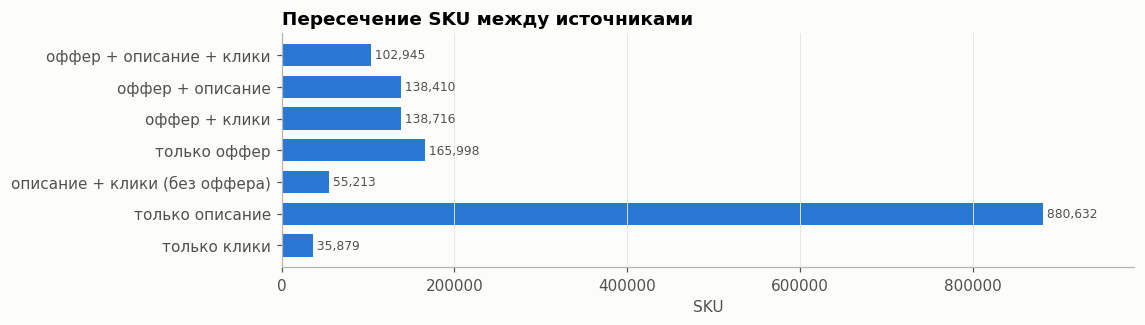

офферов с описанием: 44.2%; кликнутых офферов: 44.3%


In [6]:
S_off, S_desc, S_clk = set(offers.sku_id), set(desc_meta.sku_id), set(clicks_sku.sku_id)
combo = pd.Series({
    "оффер + описание + клики": len(S_off & S_desc & S_clk),
    "оффер + описание": len((S_off & S_desc) - S_clk),
    "оффер + клики": len((S_off & S_clk) - S_desc),
    "только оффер": len(S_off - S_desc - S_clk),
    "описание + клики (без оффера)": len((S_desc & S_clk) - S_off),
    "только описание": len(S_desc - S_off - S_clk),
    "только клики": len(S_clk - S_off - S_desc),
})
ax = hbar(combo, title="Пересечение SKU между источниками", xlabel="SKU")
plt.show()
print(f"офферов с описанием: {len(S_off & S_desc)/len(S_off):.1%}; кликнутых офферов: {len(S_off & S_clk)/len(S_off):.1%}")

In [7]:
# 1P/3P: диапазон ID против поля «Продавец»
seller = read_rg(DATA / "params.parquet", ["offer_id", "param_name", "value"],
                 lambda t: pc.equal(t["param_name"], "Продавец")).to_pandas()[["offer_id", "value"]]
offers = offers.merge(seller.drop_duplicates("offer_id").rename(columns={"value": "seller"}), on="offer_id", how="left")
offers = offers.drop(columns=["name", "model"])
del seller; free()
# сегмент определяем по продавцу: диапазон ID его не восстанавливает (см. таблицу)
offers["seg"] = np.select([offers.seller.eq("М.Видео"), offers.seller.notna()], ["1P", "3P"], "нет продавца")
offers["id_range"] = np.where(offers.sku_id >= 400_000_000, "≥ 400 млн", "< 100 млн")
pd.crosstab(offers.id_range, offers.seg, margins=True)

seg,1P,3P,нет продавца,All
id_range,,,,
< 100 млн,33665,30528,36,64229
≥ 400 млн,51196,430352,292,481840
All,84861,460880,328,546069


**Вывод 1.**
* Атрибуты (разметку) даёт только фид `skus.pkl`, тексты описаний — только `sku_desc`. Рабочий **размеченный корпус** для обучения
  и оценки — пересечение «оффер + описание» (≈241 тыс. карточек). Остальные 936 тыс. описаний (79%) без меток **и без категории** —
  это основная масса карточек для инференса, ими занимается раздел 9.
* Клики есть у ~44% офферов — по ним считаем веса «качества с учётом трафика».
* **Диапазон ID не разделяет 1P и 3P**: среди `sku_id < 100 млн` почти половина офферов (30.5 тыс. из 64 тыс.) от сторонних продавцов,
  а среди `≥ 400 млн` — 51 тыс. офферов М.Видео. Сегмент берём по полю «Продавец»: 1P — 84.9 тыс. офферов (16%),
  3P — 460.9 тыс., у 328 продавец не указан. Это и есть срез для оценки fairness.

## 2. Тексты карточек

In [8]:
# статистики считаем по row group'ам: весь файл описаний в памяти занимает ~2 ГБ
pf_d = pq.ParquetFile(RAW / "sku_desc.parquet")
parts, hashes = [], []
for i in range(pf_d.num_row_groups):
    dt = pf_d.read_row_group(i)
    parts.append(pd.DataFrame({
        "sku_id": dt["sku_id"].to_numpy(),
        "title_len": pc.utf8_length(dt["title"]).to_numpy(),
        "desc_len": pc.utf8_length(dt["description"]).to_numpy(),
        "has_html": pc.match_substring_regex(dt["description"], r"<[a-zA-Z/][^>]*>").to_numpy(),
        "has_char_block": pc.match_substring(dt["description"], "Характеристики").to_numpy(),
        "has_bullets": pc.match_substring(dt["description"], "•").to_numpy(),
        # ≥ 3 строк вида «Ключ: значение» (строка начинается с начала текста, \n, <br> или буллета)
        "has_kv": pc.greater_equal(pc.count_substring_regex(
            dt["description"], r"(?:^|\n|<br\s*/?>)\s*[•\-–]?\s*[A-ZА-ЯЁ][^:<\n]{1,40}:\s*[^\s<]"), 3).to_numpy(),
    }))
    hashes.append(pd.util.hash_array(dt["description"].to_numpy(zero_copy_only=False)))
dd = pd.concat(parts, ignore_index=True)
dd["has_offer"] = dd.sku_id.isin(S_off)
dd["seg"] = dd.sku_id.map(offers.set_index("sku_id").seg).fillna("нет оффера")
dup_desc = 1 - len(np.unique(np.concatenate(hashes))) / len(dd)
del dt, parts, hashes, desc_meta, S_desc, S_clk; free()

print(f"дублей описаний: {dup_desc:.1%};  описаний короче 50 символов: {(dd.desc_len < 50).mean():.1%}")
seg_tab = dd.groupby("seg").agg(
    карточек=("sku_id", "size"), title_len_med=("title_len", "median"), desc_len_med=("desc_len", "median"),
    html=("has_html", "mean"), характеристики=("has_char_block", "mean"), буллеты=("has_bullets", "mean"),
    ключ_значение=("has_kv", "mean"))
seg_tab.loc["всего"] = [len(dd), dd.title_len.median(), dd.desc_len.median(), dd.has_html.mean(),
                        dd.has_char_block.mean(), dd.has_bullets.mean(), dd.has_kv.mean()]
seg_tab.style.format({c: "{:.0%}" for c in ["html", "характеристики", "буллеты", "ключ_значение"]} | {"карточек": "{:,.0f}"})

дублей описаний: 22.1%;  описаний короче 50 символов: 0.2%


,карточек,title_len_med,desc_len_med,html,характеристики,буллеты,ключ_значение
seg,,,,,,,
1P,"56,342",49.000000,924.000000,81%,0%,25%,2%
3P,"184,929",58.000000,1078.000000,72%,3%,7%,9%
нет оффера,"935,845",39.000000,481.000000,43%,36%,38%,38%
нет продавца,84,36.000000,1045.000000,100%,2%,45%,2%
всего,"1,177,200",43.000000,630.000000,49%,29%,32%,31%


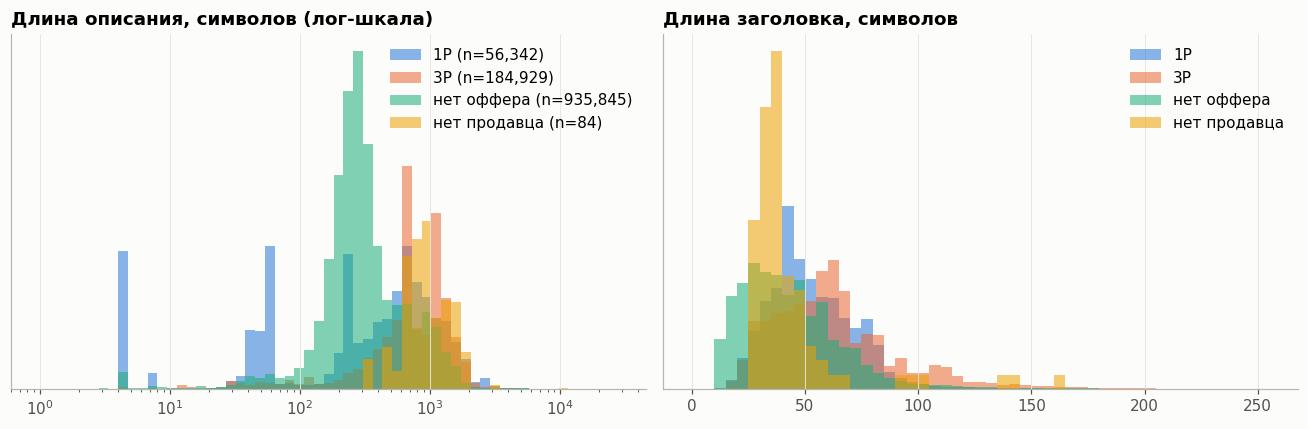

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.logspace(0, np.log10(dd.desc_len.max() + 1), 60)
for i, (seg, g) in enumerate(dd.groupby("seg")):
    axes[0].hist(g.desc_len.clip(lower=1), bins=bins, alpha=0.55, color=C[i], label=f"{seg} (n={len(g):,})", density=True)
    axes[1].hist(g.title_len, bins=np.arange(0, 260, 5), alpha=0.55, color=C[i], label=seg, density=True)
axes[0].set_xscale("log"); axes[0].set_title("Длина описания, символов (лог-шкала)"); axes[0].legend()
axes[1].set_title("Длина заголовка, символов"); axes[1].legend()
for a in axes: a.set_yticks([])
plt.tight_layout(); plt.show()

In [10]:
off_ids = pa.array(list(S_off), pa.int64())
t = pq.ParquetFile(RAW / "sku_desc.parquet").read_row_group(0)
sample_desc = t.filter(pc.is_in(t["sku_id"], value_set=off_ids)).to_pandas()
del t; free()
for _, r in sample_desc.sample(3, random_state=7).iterrows():
    print(f"[{r.sku_id}] {r.title}\n   {r.description[:400]}\n")

[400903995] Напильник No Name Набор напильников Biber 85306 Мастер, 200 мм (5 шт.)
   Набор напильников Biber 85306 Мастер, 200 мм (5 шт.). Применяются для специальных работ по обработке деревянных, металлических, пластиковых деталей, для снятия заусенцев и выправления неровностей. Закаленная инструментальная сталь У8. Двойная насечка №2. Размер, мм: 200. Вес брутто, кг: 0,66.

[400738251] Миксер Centek CT-1138
   Планетарный миксер Centek — это мощное и универсальное устройство, которое станет отличным решением для вашей домашней кухни, сочетая высокое качество и эффективность в процессе приготовления разнообразных блюд. Вы сможете легко адаптировать скорость, достигая идеальных результатов при работе с ингредиентами, будь то замешивание теста или взбивание кремов. Особая функция планетарного смешивания об

[401000257] Столешница для ванной КДМ Столешница из акрилового камня
   Акриловые столешницы, подоконники и полки из акрилового камня доступны в <b>8 цветах</b> и широкой сетке раз

**Вывод 2.**
* Описания длинные: медиана 630 символов (1P — 924, 3P — 1 078, карточки без оффера — 481). HTML (`<br>`, `<b>`) есть у 81% описаний 1P,
  72% 3P и 43% карточек без оффера. Перед regex и эмбеддингами нужна очистка.
* **Структурированные блоки есть почти только у карточек без оффера**: «Характеристики» — 36%, ≥ 3 строк «Ключ: значение» — 38%.
  У офферов из фида таких описаний 0–3% и 2–9%. Парсер пар — дешёвый источник атрибутов именно для основной массы инференса,
  но на размеченной части его почти не на чем проверить: для него нужен отдельный gold-сет из карточек без оффера.
* 22% описаний дублируются: это шаблонные тексты продавцов или одинаковый текст у вариантов товара. При сплите
  дубли надо держать в одной части, иначе оценка будет завышена.
* Заголовок короткий и плотный (бренд, модель, память, цвет, артикул) — главный источник для правил; описание — для длинного хвоста.
* e5-small имеет лимит 512 токенов: описание надо резать на фрагменты, а не кодировать целиком.

## 3. Категории и продавцы: длинный хвост

In [11]:
par, nm = dict(zip(cats.id, cats.parent_id)), dict(zip(cats.id, cats.name))
def cat_path(i):
    out = []
    while i is not None and i in nm and len(out) < 10:
        out.append(nm[i]); i = par.get(i)
    return out[::-1]
paths = {i: cat_path(i) for i in offers.category_id.unique()}
offers["l1"] = offers.category_id.map(lambda i: (paths[i] or ["<нет в дереве>"])[0])
offers["leaf"] = offers.category_id.map(lambda i: (paths[i] or ["<нет в дереве>"])[-1])
offers["depth"] = offers.category_id.map(lambda i: len(paths[i]))

print("категорий в дереве:", len(cats), "| корней:", cats.parent_id.isna().sum(),
      "| листьев с офферами:", offers.category_id.nunique(),
      "| глубина пути:", offers.depth.value_counts().to_dict())
leaf_n = offers.category_id.value_counts()
leaf_n.describe(percentiles=[.25, .5, .75, .9, .99]).round(1).to_frame("офферов в листе").T

категорий в дереве: 6963 | корней: 96 | листьев с офферами: 3599 | глубина пути: {3: 546030, 0: 39}


,count,mean,std,min,25%,50%,75%,90%,99%,max
офферов в листе,3599.0,151.7,1298.7,1.0,3.0,10.0,45.0,183.0,2401.3,54760.0


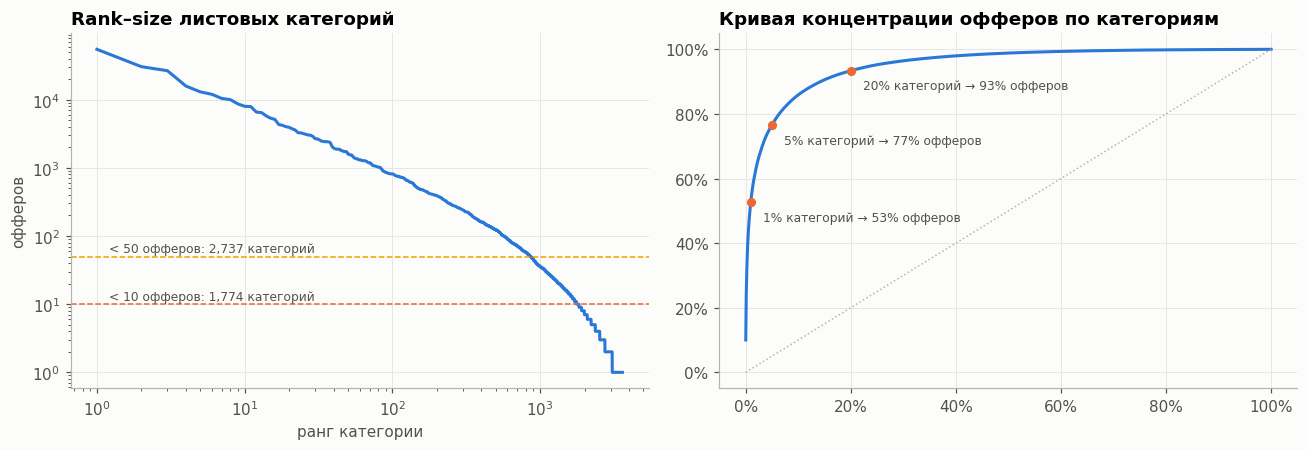

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
r = np.arange(1, len(leaf_n) + 1)
axes[0].loglog(r, leaf_n.values, color=C[0], lw=2)
axes[0].set_title("Rank–size листовых категорий"); axes[0].set_xlabel("ранг категории"); axes[0].set_ylabel("офферов")
for thr, col in [(10, C[1]), (50, C[3])]:
    k = (leaf_n >= thr).sum()
    axes[0].axhline(thr, color=col, lw=1, ls="--"); axes[0].text(1.2, thr * 1.15, f"< {thr} офферов: {len(leaf_n)-k:,} категорий", color=INK2, fontsize=8)
cum = leaf_n.cumsum() / leaf_n.sum()
axes[1].plot(r / len(r), cum.values, color=C[0], lw=2)
axes[1].plot([0, 1], [0, 1], color=GRAY, lw=1, ls=":")
for q in [0.01, 0.05, 0.2]:
    y = cum.iloc[int(q * len(r)) - 1]
    axes[1].scatter([q], [y], color=C[1], s=25, zorder=3); axes[1].annotate(f"{q:.0%} категорий → {y:.0%} офферов", (q, y), xytext=(8, -12), textcoords="offset points", fontsize=8, color=INK2)
axes[1].xaxis.set_major_formatter(pct); axes[1].yaxis.set_major_formatter(pct)
axes[1].set_title("Кривая концентрации офферов по категориям")
plt.tight_layout(); plt.show()

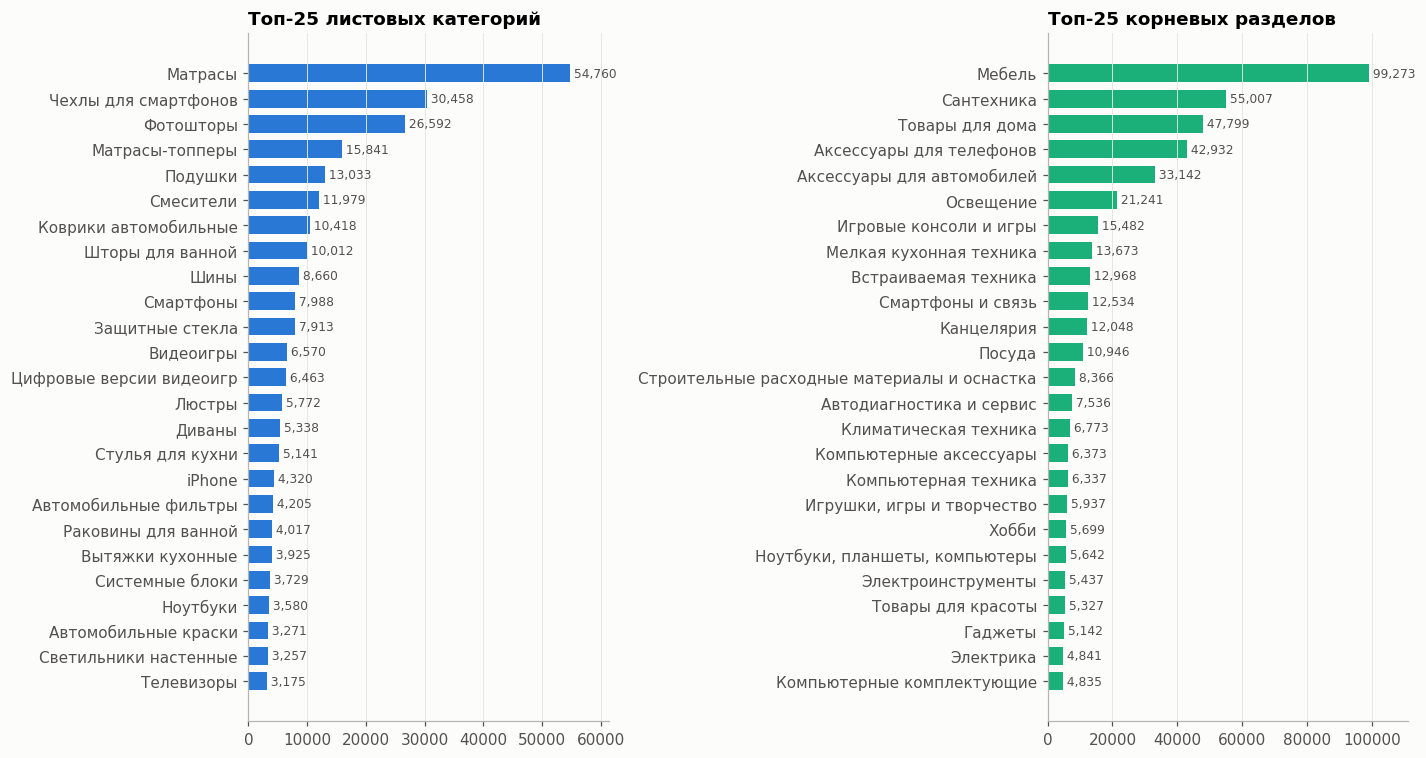

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 7))
hbar(offers.leaf.value_counts().head(25), ax=axes[0], title="Топ-25 листовых категорий")
hbar(offers.l1.value_counts().head(25), ax=axes[1], title="Топ-25 корневых разделов", color=C[2])
plt.tight_layout(); plt.show()

Каталог **не про электронику в первую очередь**, как обещало ТЗ: больше всего матрасов, чехлов, фотоштор, подушек, смесителей.
Смартфоны (≈8 тыс.) и ноутбуки (≈3.6 тыс.) — средние по размеру категории. Значит, схемы и правила
нельзя писать руками под пару категорий — они должны выводиться из данных автоматически.

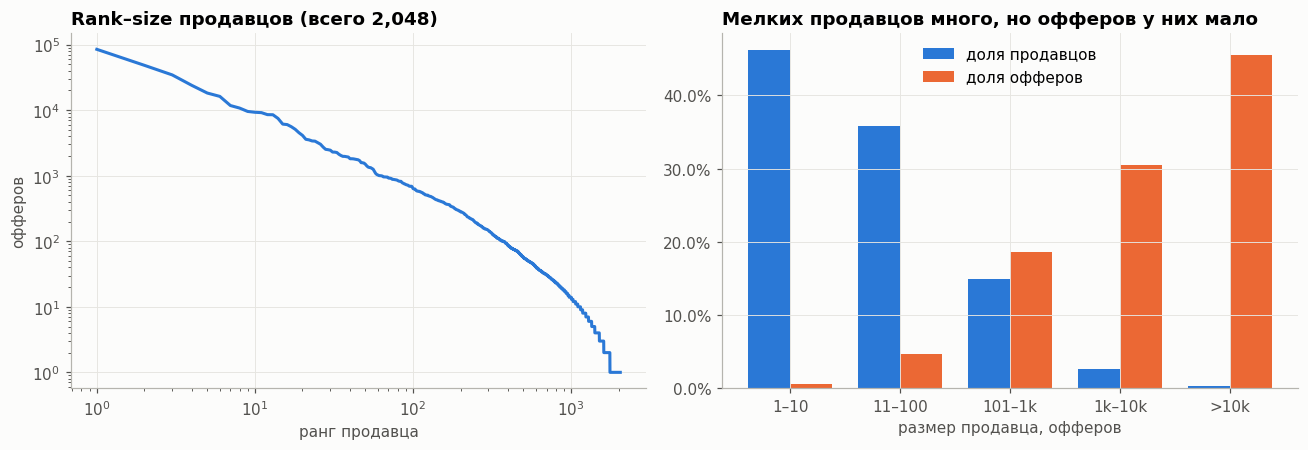

топ-5 продавцов: {'М.Видео': 84861, 'продавец #2': 48366, 'продавец #3': 34531, 'продавец #4': 23837, 'продавец #5': 18261} 
медиана категорий на продавца: 2.0


In [14]:
sel_n = offers.seller.value_counts()
mask = {s: (s if s == "М.Видео" else f"продавец #{i}") for i, s in enumerate(sel_n.index, 1)}  # имена ИП не выводим
offers["seller_id"] = offers.seller.map(mask)
sel_n.index = sel_n.index.map(mask)
cats_per_seller = offers.groupby("seller_id").category_id.nunique()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].loglog(np.arange(1, len(sel_n) + 1), sel_n.values, color=C[0], lw=2)
axes[0].set_title(f"Rank–size продавцов (всего {len(sel_n):,})"); axes[0].set_xlabel("ранг продавца"); axes[0].set_ylabel("офферов")
bins_s = [0, 10, 100, 1000, 10_000, 1e6]
lbl = ["1–10", "11–100", "101–1k", "1k–10k", ">10k"]
size_b = pd.cut(sel_n, bins_s, labels=lbl)
share = pd.DataFrame({"продавцов": size_b.value_counts().reindex(lbl) / len(sel_n),
                      "офферов": sel_n.groupby(size_b).sum().reindex(lbl) / sel_n.sum()})
x = np.arange(len(lbl)); w = 0.38
axes[1].bar(x - w/2, share["продавцов"], w, color=C[0], label="доля продавцов")
axes[1].bar(x + w/2, share["офферов"], w, color=C[1], label="доля офферов")
axes[1].set_xticks(x, lbl); axes[1].set_xlabel("размер продавца, офферов"); axes[1].yaxis.set_major_formatter(pct)
axes[1].set_title("Мелких продавцов много, но офферов у них мало"); axes[1].legend()
plt.tight_layout(); plt.show()
offers["seller_size"] = offers.seller_id.map(pd.cut(sel_n, bins_s, labels=lbl))
print("топ-5 продавцов:", sel_n.head(5).to_dict(), "\nмедиана категорий на продавца:", cats_per_seller.median())

**Вывод 3.**
* 3.6 тыс. листовых категорий, **медиана — 10 офферов**, у половины категорий меньше 10 примеров. Ручные правила под категорию не масштабируются,
  схему нужно выводить из данных, а для хвоста опираться на общие (межкатегорийные) атрибуты: бренд, цвет, размеры, вес, материал.
* 2 тыс. продавцов, сильная концентрация: несколько крупных дают основной объём. Если метрику считать «в среднем по карточкам»,
  мелкие продавцы и редкие категории в ней растворятся — **оцениваем macro по категориям и срезам размера продавца**.
* Для проверки «новых категорий» разумно отложить часть листовых категорий целиком (group split по `category_id`).

## 4. Атрибуты: что является разметкой

In [15]:
# словарное кодирование сразу при чтении: offer_id/param_name/unit становятся category
t = pq.read_table(DATA / "params.parquet", read_dictionary=["offer_id", "param_name", "unit"])
params = t.to_pandas(self_destruct=True, split_blocks=True)  # arrow-буферы освобождаются по ходу конвертации
del t; free()
# вычисляем по словарю категорий и раскладываем по кодам — экономит память на 21 млн строк
names_ = params.param_name.cat.categories
codes_ = params.param_name.cat.codes.to_numpy()
params["is_search"] = np.asarray(names_.str.endswith("_search"))[codes_]
base_ = names_.str.replace("_search", "", regex=False)
uniq_base_ = pd.Index(base_.unique())
params["base"] = pd.Categorical.from_codes(uniq_base_.get_indexer(base_)[codes_], uniq_base_)
print(f"строк: {len(params):,} | уникальных имён: {params.param_name.nunique():,} | "
      f"_search: {params.is_search.mean():.0%} | с единицей измерения: {params.unit.notna().mean():.1%}")

ex = params[params.offer_id == offers.offer_id[offers.leaf.eq("Смартфоны")].iloc[0]]
ex[["param_name", "value", "unit"]].head(40)

строк: 20,975,731 | уникальных имён: 12,999 | _search: 69% | с единицей измерения: 13.3%


,param_name,value,unit
2953,Потратить бонусы,Да,NaN
2954,Быстрая зарядка,Да,NaN
2955,Технология экрана,AMOLED,NaN
2956,Вес,150 - 200 г,NaN
2957,Разъем для наушников,USB Type-C,NaN
2958,Материал корпуса,Комбинированный,NaN
2959,Беспроводная зарядка,Да,NaN
2960,Встроенная память,128 ГБ,NaN
2961,Цвет,белый,NaN
2962,Производитель процессора,Samsung,NaN


В фиде у атрибута **два слоя**:
* `Имя_search` — исходное, «сырое» значение из мастер-данных/от продавца (`Цвет_search = мятный`, `Емкость аккумулятора_search = 5000 мАч`);
* `Имя` без суффикса — **фасет для фильтров** с каноническим, часто «корзинным» значением (`Цвет = зеленый`, `Ширина = 80 - 120 мм`).

Плюс служебные поля, которые к характеристикам товара не относятся: `Продавец`, `Подборки`, `Акции`, `Потратить бонусы`, `Топ коллекция`, `… для отчета BI/BO`.
Для нашей задачи `_search` — то, что нужно **извлечь**, фасет — то, к чему нужно **нормализовать** (справочник). Пары
«сырое → фасет» — готовые обучающие примеры нормализатора.

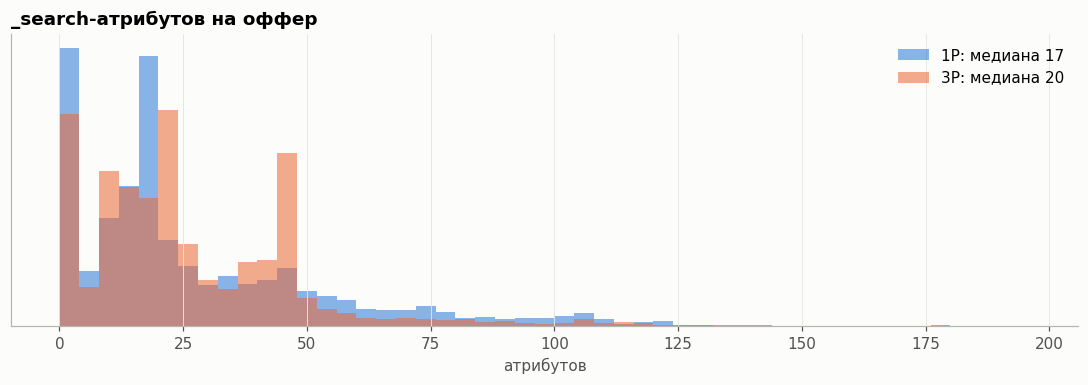

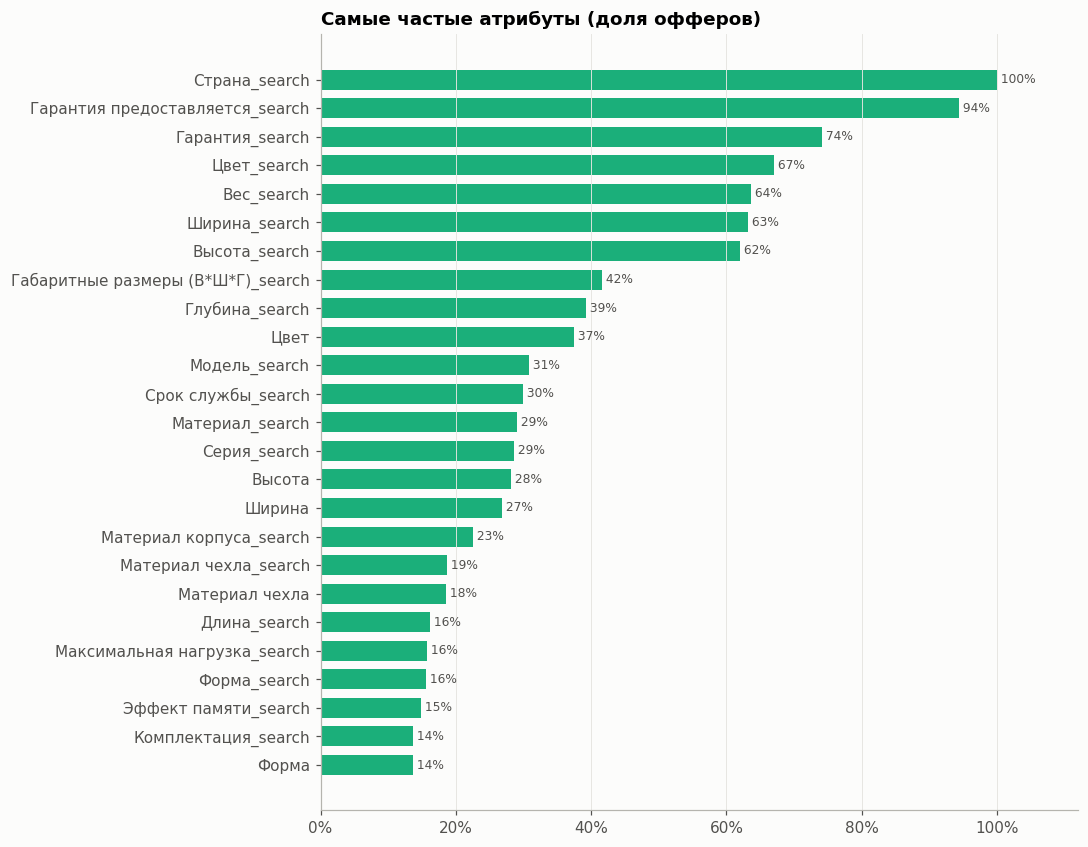

In [16]:
SERVICE = re.compile(r"^(Продавец|Подборки|Акции|Потратить бонусы|Топ коллекция|ЗД для отчета|ЖД для отчета|Обяз\. к предустановке)")
service_name = np.asarray(base_.str.match(SERVICE))
params["service"] = service_name[codes_]
# считаем через bincount по кодам — без копий таблицы в 21 млн строк
oc = params.offer_id.cat.codes.to_numpy()
per_offer = pd.DataFrame({
    "n_all": np.bincount(oc),
    "n_search": np.bincount(oc, weights=params.is_search.to_numpy()).astype(int),
}, index=params.offer_id.cat.categories.astype(str))
per_offer["n_facet"] = per_offer.n_all - per_offer.n_search
offers = offers.merge(per_offer, left_on="offer_id", right_index=True, how="left")

fig, ax = plt.subplots(figsize=(10, 3.6))
for i, seg in enumerate(["1P", "3P"]):
    g = offers[offers.seg == seg]
    ax.hist(g.n_search, bins=np.arange(0, 200, 4), alpha=0.55, color=C[i], density=True, label=f"{seg}: медиана {g.n_search.median():.0f}")
ax.set_title("_search-атрибутов на оффер"); ax.legend(); ax.set_yticks([]); ax.set_xlabel("атрибутов")
plt.tight_layout(); plt.show()
name_cnt = pd.Series(np.bincount(codes_, minlength=len(names_)), index=names_)
top_names = name_cnt[~service_name].sort_values(ascending=False).head(25) / len(offers)
hbar(top_names, title="Самые частые атрибуты (доля офферов)", fmt="{:.0%}", color=C[2])
plt.tight_layout(); plt.show()

In [17]:
by_size = offers.groupby("seller_size", observed=True)[["n_search", "n_facet"]].median()
by_size["офферов"] = offers.seller_size.value_counts()
display(by_size)
offers.groupby("seg")[["n_search", "n_facet"]].median().assign(офферов=offers.seg.value_counts())

,n_search,n_facet,офферов
seller_size,,,
1–10,21.0,8.0,3518
11–100,23.0,9.0,25835
101–1k,21.0,10.0,101540
1k–10k,16.0,8.0,166214
>10k,21.0,8.0,248634


,n_search,n_facet,офферов
seg,,,
1P,17.0,8.0,84861
3P,20.0,8.0,460880
нет продавца,27.0,15.0,328


**Вывод 4.**
* ≈13 тыс. уникальных имён атрибутов, но большинство — категорийно-специфичные; общих «сквозных» атрибутов несколько десятков.
* `_search` → что извлекать, фасет → справочник канонических значений. Служебные и маркетинговые поля исключаем из схемы.
* Плотность разметки почти не зависит от продавца: медиана 16–23 `_search`-атрибута на оффер по размеру продавца,
  17 у 1P и 20 у 3P. Эталон по продавцам сопоставим, поэтому срезы метрик 1P/3P и по размеру продавца будут честными.
* Эталон всё равно неполон: атрибута может не быть в фиде, хотя он есть в тексте. Такие предсказания нельзя автоматически
  считать FP — нужна ручная проверка выборки (gold-сет).

## 5. Обязательные атрибуты категории

Точного списка обязательных полей в данных нет, поэтому строим **схему категории автоматически**:
атрибут обязательный, если он (а) фасет, т.е. участвует в фильтрах, (б) заполнен у ≥ 70% офферов категории, (в) не служебный.
Ниже — проверка, что такое правило восстанавливает списки из ТЗ для смартфонов и ноутбуков.

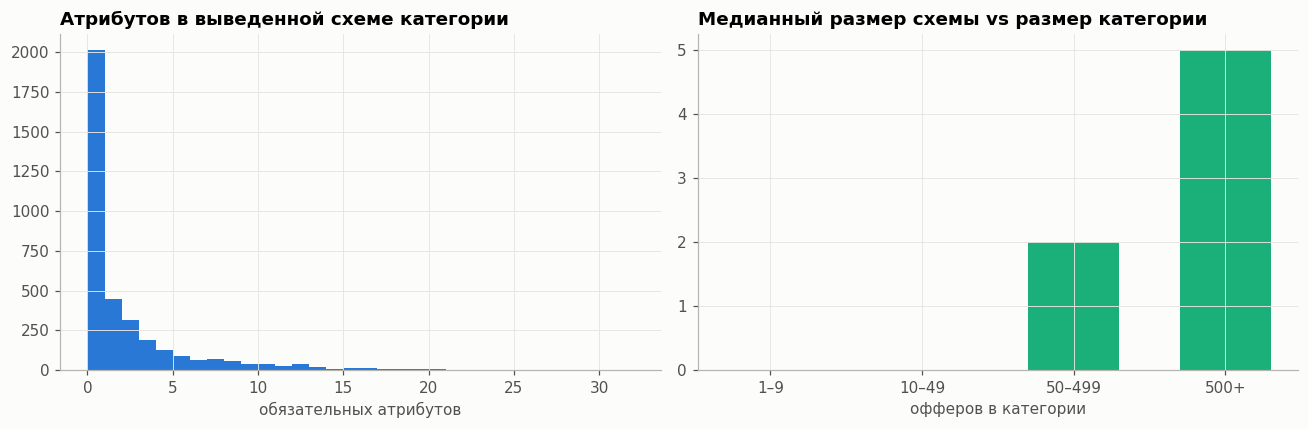

категорий с пустой схемой: 55.9%; офферов в них: 21.7%; офферов в категориях 1–9 товаров: 1.1%


In [18]:
leaf_of = dict(zip(offers.offer_id, offers.category_id))
facets = params.loc[~params.is_search & ~params.service, ["offer_id", "param_name"]].drop_duplicates()
facets["cat"] = facets.offer_id.map(leaf_of)
fill = facets.groupby(["cat", "param_name"], observed=True).size().rename("n").reset_index()
fill["fill"] = fill.n / fill.cat.map(leaf_n)
schema = fill[fill.fill >= 0.7]
schema_size = schema.groupby("cat").size().reindex(leaf_n.index, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(schema_size, bins=np.arange(0, schema_size.max() + 2), color=C[0])
axes[0].set_title("Атрибутов в выведенной схеме категории"); axes[0].set_xlabel("обязательных атрибутов")
sz = pd.cut(leaf_n, [0, 9, 49, 499, 1e6], labels=["1–9", "10–49", "50–499", "500+"])
axes[1].bar(sz.cat.categories, schema_size.groupby(sz).median(), color=C[2], width=0.6)
axes[1].set_title("Медианный размер схемы vs размер категории"); axes[1].set_xlabel("офферов в категории")
plt.tight_layout(); plt.show()
empty = schema_size[schema_size == 0].index
print(f"категорий с пустой схемой: {(schema_size == 0).mean():.1%}; "
      f"офферов в них: {leaf_n[empty].sum() / leaf_n.sum():.1%}; "
      f"офферов в категориях 1–9 товаров: {leaf_n[leaf_n < 10].sum() / leaf_n.sum():.1%}")

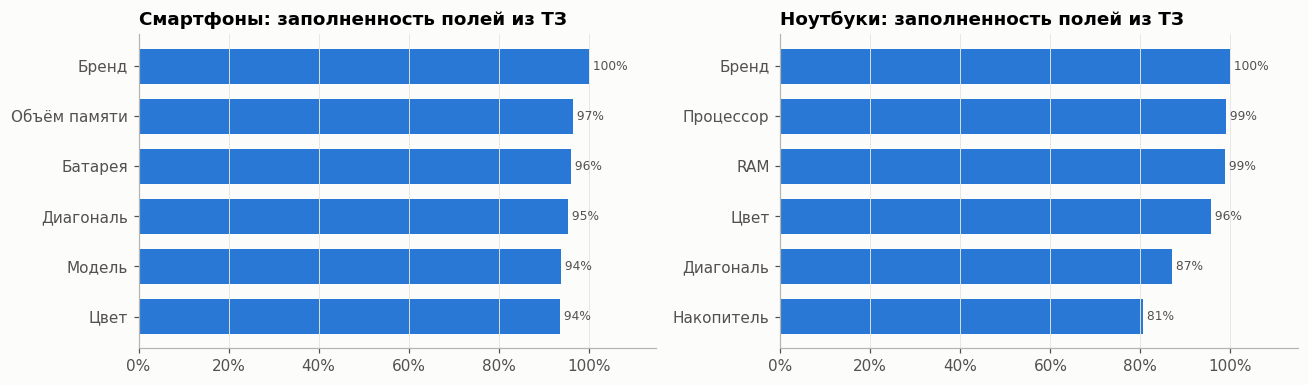

In [19]:
# ТЗ → имена полей фида (бренд — это vendor оффера)
TZ = {
    "Смартфоны": {"Бренд": "vendor", "Модель": "Модель_search", "Объём памяти": "Встроенная память (ROM)_search",
                  "Диагональ": "Диагональ_search", "Батарея": "Емкость аккумулятора_search", "Цвет": "Цвет_search"},
    "Ноутбуки": {"Бренд": "vendor", "Процессор": "Процессор_search", "RAM": "Оперативная память (RAM)_search",
                 "Накопитель": "Общий объем накопителя_search", "Диагональ": "Диагональ экрана_search", "Цвет": "Цвет_search"},
}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, (leaf, attrs) in zip(axes, TZ.items()):
    ids = offers.offer_id[offers.leaf == leaf]
    sub = params.loc[params.offer_id.isin(ids), ["offer_id", "param_name", "value"]]
    rows = {}
    for k, a in attrs.items():
        if a == "vendor":
            rows[k] = offers.vendor[offers.leaf == leaf].fillna("").str.len().gt(0).mean()
        else:
            rows[k] = sub.loc[sub.param_name == a, "offer_id"].nunique() / len(ids)
    hbar(pd.Series(rows).sort_values(ascending=False), ax=ax, title=f"{leaf}: заполненность полей из ТЗ", fmt="{:.0%}")
    ax.set_xlim(0, 1.15)
plt.tight_layout(); plt.show()

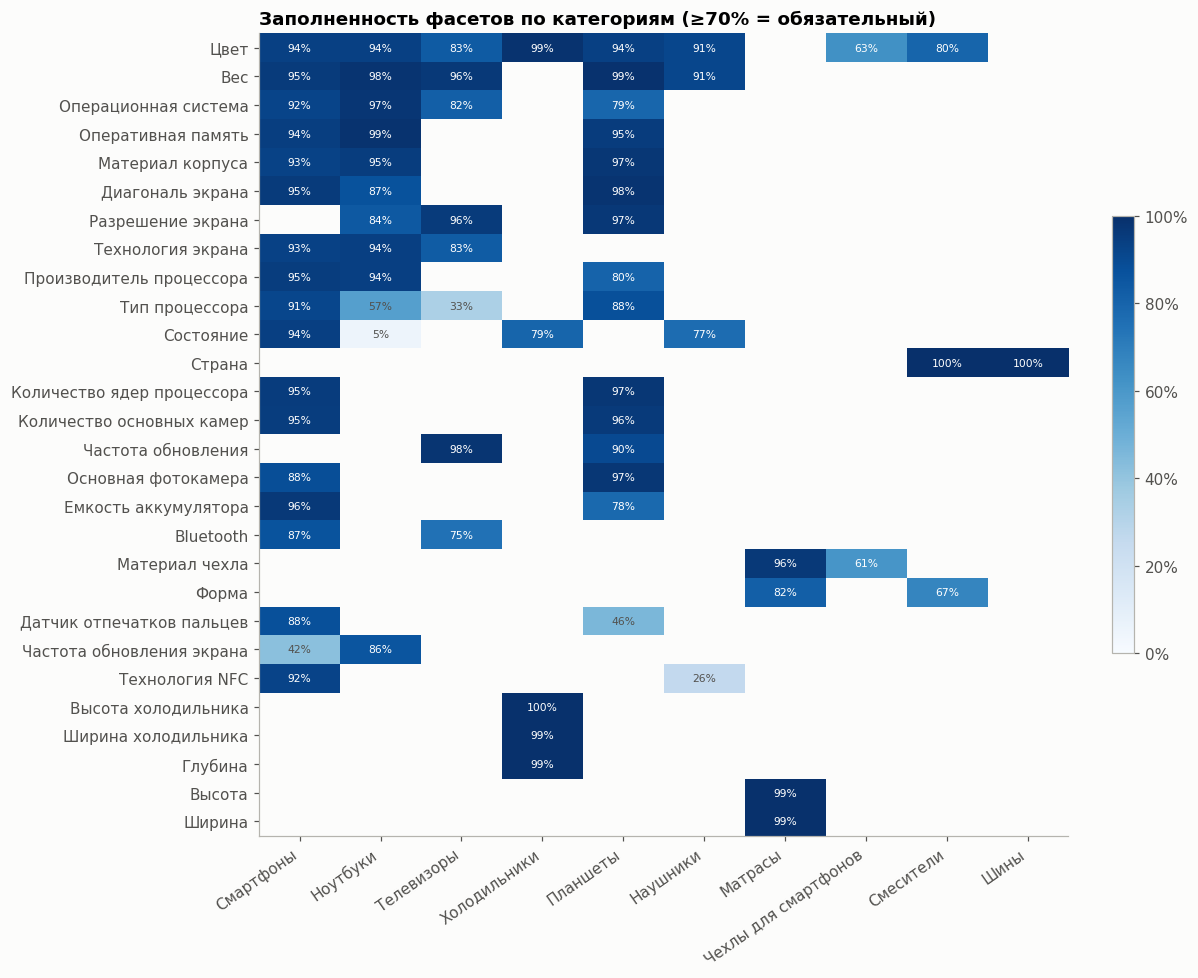

In [20]:
key_cats = ["Смартфоны", "Ноутбуки", "Телевизоры", "Холодильники", "Планшеты", "Наушники", "Матрасы", "Чехлы для смартфонов", "Смесители", "Шины"]
key_ids = {offers.category_id[offers.leaf == k].mode()[0]: k for k in key_cats}
f = fill[fill.cat.isin(key_ids)].assign(cat=lambda d: d.cat.map(key_ids))
f = f[f.param_name.isin(f.groupby("param_name", observed=True).fill.max().loc[lambda s: s > 0.7].index)]
top_attr = f.groupby("param_name", observed=True).fill.sum().sort_values(ascending=False).head(28).index
hm = f.pivot_table(index="param_name", columns="cat", values="fill", observed=True).reindex(top_attr)[key_cats].fillna(0)

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(np.ma.masked_equal(hm.values, 0), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(key_cats)), key_cats, rotation=35, ha="right"); ax.set_yticks(range(len(hm)), hm.index)
for (y, x), v in np.ndenumerate(hm.values):
    if v > 0: ax.text(x, y, f"{v:.0%}", ha="center", va="center", fontsize=7, color="white" if v > 0.6 else INK2)
ax.grid(False); ax.set_title("Заполненность фасетов по категориям (≥70% = обязательный)")
plt.colorbar(im, ax=ax, fraction=0.025, format=pct); plt.tight_layout(); plt.show()

**Вывод 5.**
* Поля из ТЗ для смартфонов и ноутбуков в фиде заполнены на 80–100% — их можно использовать как эталон.
* Правило «фасет + fill ≥ 70%» даёт осмысленные схемы для крупных категорий. У 56% листовых категорий схема получается
  пустой, но в них лежит только ~22% офферов: проблема в основном в мелких и средних категориях без фасетов.
  Для них схему наследуем от родительской категории (L2/L1) — это шаг 1 пайплайна. Порог 70% используем везде одинаково.
* Цвет — сквозной атрибут почти всех категорий: один словарь цветов окупается на всём каталоге.

## 6. Значения: насколько нужна нормализация

In [21]:
def vals_u(name):
    # единица часто лежит не в значении, а в атрибуте @unit: «8» + «МБ». Склеиваем до любой обработки
    m = params.param_name == name
    v, u = params.loc[m, "value"].astype(str), params.loc[m, "unit"].astype(object)
    return v.where(u.isna(), v + " " + u.astype(str))

def card(name):
    v = vals_u(name)
    vl = v.str.lower().str.replace("ё", "е")
    return pd.Series({"заполнено": len(v), "уникальных": v.nunique(), "уникальных после lower+ё→е": vl.nunique(),
                      "топ-10 покрывают": v.value_counts().head(10).sum() / max(len(v), 1)})
names = ["Цвет_search", "Цвет", "Материал_search", "Материал", "Модель_search", "Серия_search",
         "Диагональ_search", "Диагональ экрана", "Встроенная память (ROM)_search", "Встроенная память",
         "Оперативная память (RAM)_search", "Процессор_search", "Емкость аккумулятора_search"]
pd.DataFrame({n: card(n) for n in names}).T.astype({"заполнено": int, "уникальных": int, "уникальных после lower+ё→е": int}).style.format({"топ-10 покрывают": "{:.0%}"})

,заполнено,уникальных,уникальных после lower+ё→е,топ-10 покрывают
Цвет_search,366130,1635,1558,75%
Цвет,204158,699,669,74%
Материал_search,158777,716,675,67%
Материал,70771,230,218,83%
Модель_search,167904,44246,43885,8%
Серия_search,156249,47436,45976,9%
Диагональ_search,19299,193,193,59%
Диагональ экрана,21784,44,44,89%
Встроенная память (ROM)_search,18688,49,48,93%
Встроенная память,12172,12,12,100%


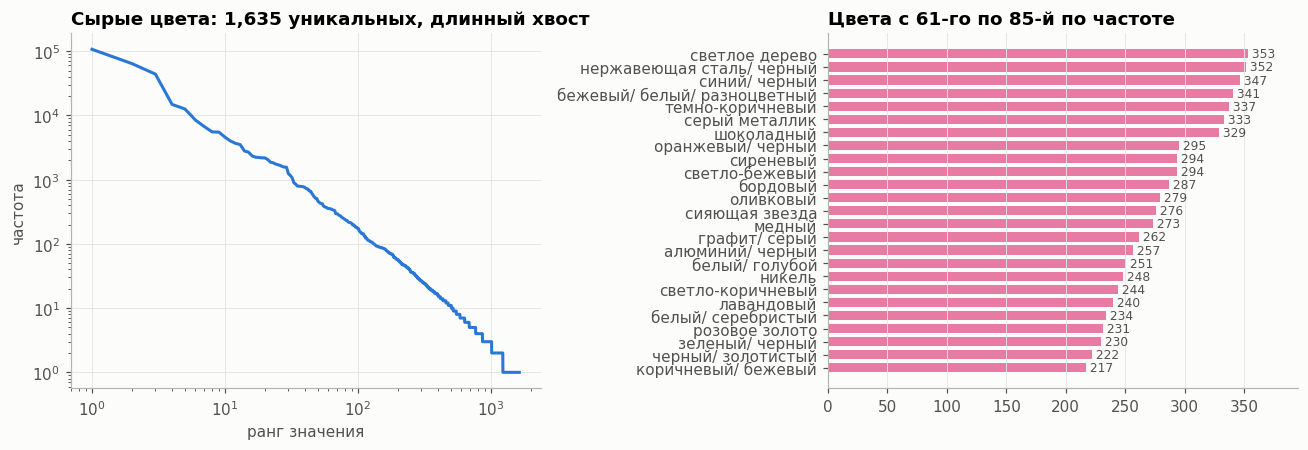

In [22]:
col = params.loc[params.param_name == "Цвет_search", "value"]
vc = col.value_counts()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].loglog(np.arange(1, len(vc) + 1), vc.values, color=C[0], lw=2)
axes[0].set_title(f"Сырые цвета: {len(vc):,} уникальных, длинный хвост"); axes[0].set_xlabel("ранг значения"); axes[0].set_ylabel("частота")
hbar(vc.iloc[60:85], ax=axes[1], title="Цвета с 61-го по 85-й по частоте", color=C[4])
plt.tight_layout(); plt.show()

In [23]:
# сырое значение → фасет: насколько отображение однозначно
w = params.loc[params.param_name.isin(["Цвет", "Цвет_search"]), ["offer_id", "param_name", "value"]].pivot_table(
    index="offer_id", columns="param_name", values="value", aggfunc="first", observed=True).dropna()
w["raw"] = w["Цвет_search"].str.lower().str.replace("ё", "е")
top_share = w.groupby("raw")["Цвет"].agg(lambda s: s.value_counts(normalize=True).iloc[0])
PLACEHOLDER = {"другой", "другие", "другие цвета", "другой цвет"}
w["facet_n"] = w["Цвет"].str.lower().str.replace("ё", "е").str.replace(r"\s*/\s*", "/", regex=True).str.strip()

def agreement(df, col):
    top = df.groupby("raw")[col].agg(lambda s: s.value_counts(normalize=True).iloc[0])
    return df.raw.map(top).mean()

clean = w[~w.facet_n.isin(PLACEHOLDER)]
print(f"пар сырой цвет → фасет: {len(w):,}")
print(f"однозначность маппинга (доля голосов за самый частый фасет):\n"
      f"  фасеты как есть:                     {agreement(w, 'Цвет'):.1%}\n"
      f"  фасеты после lower + ё→е + пробелов: {agreement(w, 'facet_n'):.1%}\n"
      f"  и без заглушек «другой/другие цвета»: {agreement(clean, 'facet_n'):.1%}  (заглушек среди фасетов: {w.facet_n.isin(PLACEHOLDER).mean():.1%})")
for raw in ["черный", "серый космос", "мятный", "графит", "бордовый"]:
    if raw in set(w.raw):
        print(f"  {raw!r:>16} →", w.loc[w.raw == raw, "Цвет"].value_counts().head(5).to_dict())
fv = params.loc[params.param_name == "Цвет", "value"]
print("\nварианты «чёрного» среди ФАСЕТОВ:", fv[fv.str.lower().str.contains("^ч[её]рн", regex=True)].value_counts().head(8).to_dict())
print("варианты «другого»:", fv[fv.str.lower().str.startswith("друг")].value_counts().to_dict())

пар сырой цвет → фасет: 203,727


однозначность маппинга (доля голосов за самый частый фасет):
  фасеты как есть:                     73.3%
  фасеты после lower + ё→е + пробелов: 75.9%
  и без заглушек «другой/другие цвета»: 86.6%  (заглушек среди фасетов: 18.2%)


          'черный' → {'черный': 44844, 'чёрный': 3709, 'Черный': 825, 'черный/серый': 534, 'Черный/Серый': 211}


    'серый космос' → {'серый космос': 90, 'серый/серебристый': 48, 'серый': 11}


          'мятный' → {'другие цвета': 143, 'зеленый': 123, 'мятный': 38, 'другой': 22, 'другие': 10}


        'бордовый' → {'бордовый': 101, 'красный': 55, 'другой': 32, 'другие цвета': 9, 'другие': 3}

варианты «чёрного» среди ФАСЕТОВ: {'черный': 50281, 'чёрный': 4178, 'черный/ красный': 1503, 'черный/ синий': 1446, 'черный/ серый': 1067, 'черный матовый': 998, 'Черный': 825, 'черный/серый': 717}
варианты «другого»: {'другой': 20593, 'другие цвета': 13862, 'другие': 1931, 'другой цвет': 327, 'Другие': 317}


атрибутов с единицей: 2,029; из них с несколькими единицами: 79


,единицы (строк)
base,
Вес,"кг (267,928), г (79,257)"
Ширина,"см (278,887), мм (65,675), м (536)"
Высота,"см (279,416), мм (59,203)"
Глубина,"см (161,703), мм (52,799)"
Длина,"см (85,800), мм (2,096), м (646), "" (1)"
Максимальная нагрузка,"кг (84,596), мА (1,372), т (35), г (5)"
Емкость аккумулятора,"мАч (15,813), Ач (837)"
Объем,"мл (9,196), л (7,192)"
Количество в упаковке,"шт (14,215), м2 (1)"


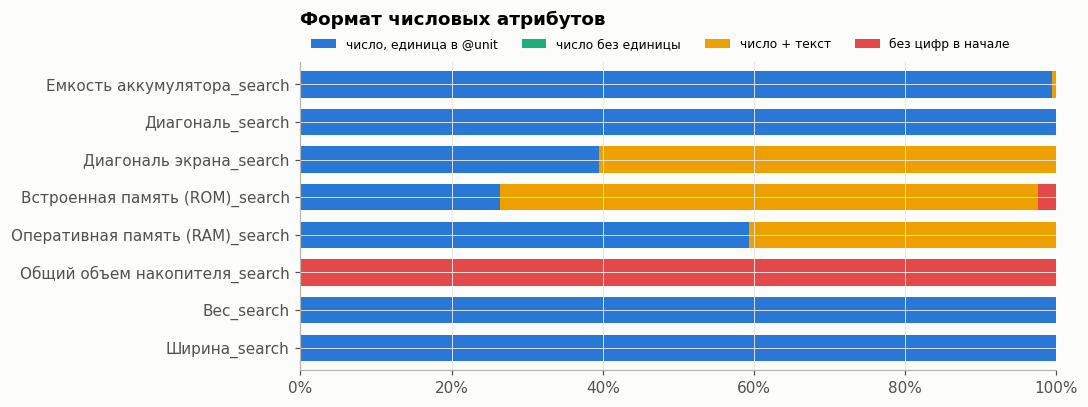

Диагональ экрана_search {'15.6"(39.6 см)': 722, '27"(68.5 см)': 684, '16"(40.6 см)': 563, '23.8"(60 см)': 407, '14"(35.5 см)': 385, '13.6"': 323, '127 см': 253, '15.3"(38.8 см)': 250}
Общий объем накопителя_search {'SSD 512 ГБ': 1590, 'SSD 1 ТБ': 844, 'SSD 256 ГБ': 370, 'SSD 2 ТБ': 53, 'HDD 512 ГБ': 16, 'SSD 4 ТБ': 3, 'SSD 512 ГБ + HDD 64 ГБ': 1, 'SSD 256 ГБ + HDD 64 ГБ': 1}


Встроенная память (ROM)_search {'256 ГБ': 6251, '512 ГБ': 3127, '128 ГБ': 3027, '8 ГБ': 1140, '1024 ГБ': 1030, '64 ГБ': 826, '32 ГБ': 630, '16 ГБ': 488}


In [24]:
u = params.loc[params.unit.notna(), ["base", "unit"]].groupby(["base", "unit"], observed=True).size()
n_units = u.groupby(level=0).size()
multi = n_units[n_units > 1].index
print(f"атрибутов с единицей: {len(n_units):,}; из них с несколькими единицами: {len(multi):,}")
mu = u[u.index.get_level_values(0).isin(multi)].reset_index(name="n")
top_multi = mu.groupby("base", observed=True).n.sum().sort_values(ascending=False).head(15).index
display(mu[mu.base.isin(top_multi)].groupby("base", observed=True).apply(
    lambda g: ", ".join(f"{r.unit} ({r.n:,})" for r in g.sort_values("n", ascending=False).itertuples())).loc[top_multi].to_frame("единицы (строк)"))

def num_share(name):
    m = params.param_name == name
    v, has_u = params.loc[m, "value"].astype(str), params.loc[m, "unit"].notna()
    bare = v.str.fullmatch(r"\d+([.,]\d+)?")
    return pd.Series({"число, единица в @unit": (bare & has_u).mean(),
                      "число без единицы": (bare & ~has_u).mean(),
                      "число + текст": (v.str.match(r"\d") & ~bare).mean(),
                      "без цифр в начале": 1 - v.str.match(r"\d").mean()})
fmt = pd.DataFrame({n: num_share(n) for n in ["Емкость аккумулятора_search", "Диагональ_search", "Диагональ экрана_search",
                                             "Встроенная память (ROM)_search", "Оперативная память (RAM)_search",
                                             "Общий объем накопителя_search", "Вес_search", "Ширина_search"]}).T
ax = fmt.plot.barh(stacked=True, color=[C[0], C[2], C[3], C[7]], figsize=(10, 3.8), width=0.7)
ax.invert_yaxis(); ax.xaxis.set_major_formatter(pct); ax.set_title("Формат числовых атрибутов", pad=24)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=4, fontsize=8)
plt.tight_layout(); plt.show()
for n in ["Диагональ экрана_search", "Общий объем накопителя_search", "Встроенная память (ROM)_search"]:
    print(n, vals_u(n).value_counts().head(8).to_dict())

### 6.1 Шум в эталоне: заглушки, многозначные атрибуты, имена полей
Эталон берём из фида, поэтому его шум напрямую попадает в метрику. Проверяем три вещи:
заглушки вместо значений, атрибуты с несколькими значениями в одном оффере и расхождение имён фасета и `_search`.

In [25]:
PLACEHOLDERS = {"другой", "другие", "другие цвета", "другой цвет", "0", "000", "-", "нет данных", "не установлена", "не указано"}
check = ["Цвет", "Цвет_search", "Гарантия_search", "Емкость аккумулятора_search", "Встроенная память (ROM)_search",
         "Оперативная память (RAM)_search", "Диагональ_search", "Процессор_search", "Модель_search"]
ph = {}
for n in check:
    v = params.loc[params.param_name == n, "value"].astype(str).str.strip().str.lower()
    ph[n] = pd.Series({"заполнено": len(v), "доля заглушек": v.isin(PLACEHOLDERS).mean(),
                       "частые заглушки": ", ".join(f"{k} ({c:,})" for k, c in v[v.isin(PLACEHOLDERS)].value_counts().head(3).items())})
display(pd.DataFrame(ph).T.sort_values("доля заглушек", ascending=False).style.format({"доля заглушек": "{:.1%}", "заполнено": "{:,}"}))

# многозначные атрибуты: одно имя встречается в оффере несколько раз
# считаем по кодам категорий: groupby по двум category-столбцам строит полное декартово произведение
keep = ~params.service.to_numpy()
pair_key = oc[keep].astype(np.int64) * len(names_) + codes_[keep]
uk, cnt = np.unique(pair_key, return_counts=True)
multi_names = pd.Series(np.bincount(uk[cnt > 1] % len(names_), minlength=len(names_)), index=names_)
multi_names = multi_names[multi_names > 0].sort_values(ascending=False)
del pair_key, uk, cnt, keep
print("атрибутов, которые бывают многозначными:", len(multi_names), "| топ:", multi_names.head(8).to_dict())

# имена: у фасета нет пары `<имя>_search`, имена с пробелами по краям
nm_all = pd.Index(names_.astype(str))
strip_bad = nm_all[nm_all != nm_all.str.strip()]
facet_nm = pd.Index([n for n in nm_all[~nm_all.str.endswith("_search")] if not SERVICE.match(n)])
search_base = set(nm_all[nm_all.str.endswith("_search")].str.replace("_search", "", regex=False).str.strip())
no_pair = facet_nm[~facet_nm.str.strip().isin(search_base)]
w_rows = name_cnt.reindex(facet_nm)
print(f"имён с пробелами по краям: {len(strip_bad)} (строк: {name_cnt.reindex(strip_bad).sum():,}), напр. {list(strip_bad[:4])}")
print(f"фасетов без одноимённого _search: {len(no_pair) / len(facet_nm):.0%} имён, {w_rows[no_pair].sum() / w_rows.sum():.0%} строк фасетов")
for f_, s_ in [("Диагональ экрана", "Диагональ_search"), ("Встроенная память", "Встроенная память (ROM)_search"),
               ("Оперативная память", "Оперативная память (RAM)_search")]:
    print(f"  {f_!r}: пара {f_ + '_search'!r} {'есть' if f_ in search_base else 'НЕТ'}; у смартфонов сырое значение лежит в {s_!r}")

,заполнено,доля заглушек,частые заглушки
Цвет,"204,158",18.1%,"другой (20,593), другие цвета (13,862), другие (2,248)"
Гарантия_search,"404,925",4.5%,"000 (18,340), не установлена (22)"
Емкость аккумулятора_search,"16,743",1.9%,0 (316)
Встроенная память (ROM)_search,"18,688",1.5%,0 (273)
Оперативная память (RAM)_search,"20,957",1.2%,"0 (244), не установлена (15)"
Модель_search,"167,904",0.0%,"- (45), 0 (12), 000 (2)"
Цвет_search,"366,130",0.0%,0 (3)
Диагональ_search,"19,299",0.0%,
Процессор_search,"12,348",0.0%,


атрибутов, которые бывают многозначными: 49 | топ: {'Внешнее покрытие': 858, 'Диагональ экрана': 808, 'Тип внутреннего покрытия': 590, 'Тип лампы': 406, 'Тип подключения': 385, 'Потребляемая мощность': 318, 'Оперативная память': 266, 'Диаметр': 200}
имён с пробелами по краям: 25 (строк: 11,240), напр. [' Количество скоростей', 'Встроенная память ', ' Резьба шпинделя', ' Линза Барлоу (2х)']
фасетов без одноимённого _search: 18% имён, 12% строк фасетов
  'Диагональ экрана': пара 'Диагональ экрана_search' есть; у смартфонов сырое значение лежит в 'Диагональ_search'
  'Встроенная память': пара 'Встроенная память_search' НЕТ; у смартфонов сырое значение лежит в 'Встроенная память (ROM)_search'
  'Оперативная память': пара 'Оперативная память_search' НЕТ; у смартфонов сырое значение лежит в 'Оперативная память (RAM)_search'


**Вывод 6.1.**
* **Заглушки в эталоне**: 18% фасетов цвета («другой», «другие цвета»), 4.5% гарантий (`000`), 1–2% батареи, ROM и RAM (`0`).
  В эталоне считаем их пропуском: не учим на них, не считаем FN и не кладём в справочник.
* **Многозначные атрибуты**: 49 атрибутов встречаются в одном оффере несколько раз (диагональ экрана, тип лампы,
  тип подключения, оперативная память). Предсказание для них — множество, метрика — F1 по множеству значений.
* **Имена полей**: 25 имён с пробелами по краям (11 тыс. строк) — `strip` до всего остального. У 18% фасетов (12% строк)
  нет одноимённого `_search` (`Встроенная память` ↔ `Встроенная память (ROM)_search`), поэтому для обязательных
  атрибутов ведём явную таблицу соответствия «фасет ↔ сырое поле».

**Вывод 6.**
* Простое `lower + ё→е` уже схлопывает часть «уникальных» значений (цвет: 1 635 → 1 558) — это первый дешёвый шаг нормализации.
* Цвет: >1.5 тыс. сырых значений с маркетинговыми названиями («серый космос», «сияющая звезда»). Однозначность маппинга
  сырой цвет → фасет: 73% на фасетах как есть, 76% после чистки написания и **87% без заглушек**. Главный источник
  «неоднозначности» — не синонимы, а заглушки «другой / другие цвета» (18% фасетов цвета). Настоящая неоднозначность ~13%:
  её закрывают словарь + retrieval по справочнику фасетов.
* Фасеты сами не канонизированы (`черный`/`чёрный`/`Черный`, `другой`/`другие цвета`) — **справочник нужно
  предварительно чистить**, иначе метрика будет штрафовать за верный, но иначе записанный ответ.
* Единица часто лежит не в значении, а в атрибуте `@unit` (`8` + `ГБ`, `127` + `см`): склеиваем их до любой обработки.
  Числовые атрибуты бывают «число + текст» (`15.6"(39.6 см)`, `SSD 512 ГБ`) и в разных единицах — regex с конвертацией
  и сравнение в каноническом числе (ГБ, дюймы, мАч).

## 7. Grounding: есть ли значение атрибута в тексте карточки

Главный вопрос для архитектуры: **какая доля эталонных значений вообще присутствует в тексте**.
Если значения в тексте нет — его нельзя честно извлечь (и LLM, которая его «знает», галлюцинирует с т.з. ТЗ).
Проверяем по смартфонам и ноутбукам: значение найдено целиком в заголовке, только в описании, только после словаря синонимов
цветов (`Titanium Grey` → `серый`), частично (≥ половины токенов, например `Intel Core i5 13420H` без частоты `2.1 ГГц`) или нигде.
Единица из `@unit` приклеивается к значению. Перед сравнением: удаление HTML, lower, ё→е, `6,7`→`6.7`,
`512GB`→`512 гб`, `1024 ГБ` ≡ `1 ТБ`. Числа ищем как числа; однозначные числа не считаем (слишком много ложных совпадений).

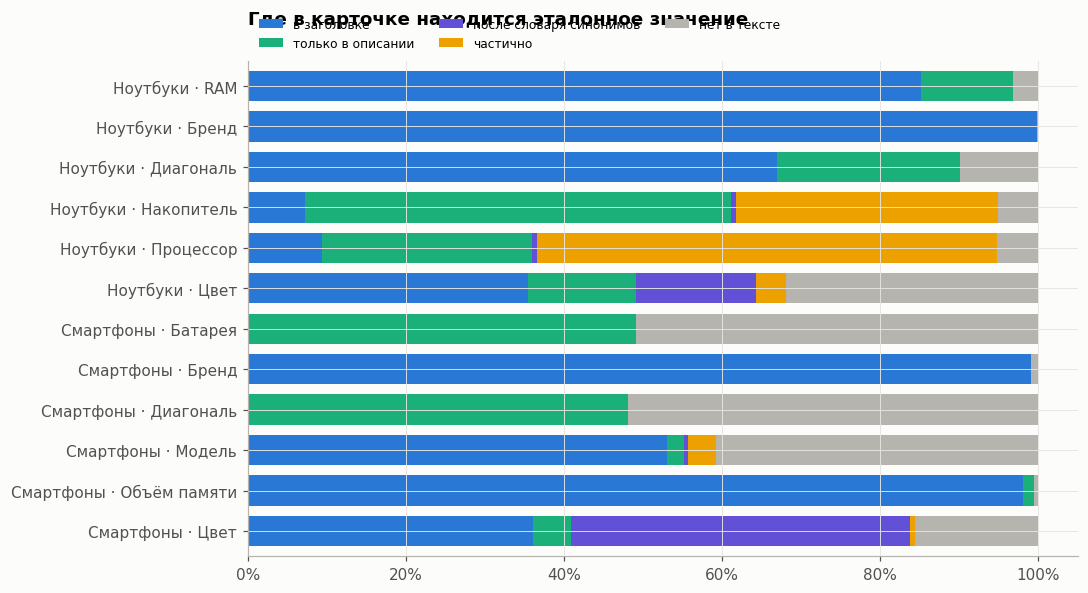

In [26]:
TAG = re.compile(r"<[^>]+>")
UNIT_EN = {"gb": "гб", "tb": "тб", "mb": "мб", "mah": "мач", "ghz": "ггц", "inch": '"', "дюйм": '"', "дюйма": '"', "дюймов": '"'}
UNIT_TOK = {"гб", "тб", "мб", "мач", "ггц", "см", "мм", "г", "кг", '"'}

# англ. и рус. синонимы цветов → одно русское слово (минимальный словарь для проверки, в пайплайне он больше)
COLOR_SYN = {"black": "черный", "white": "белый", "grey": "серый", "gray": "серый", "silver": "серебристый",
             "gold": "золотой", "golden": "золотой", "золотистый": "золотой", "blue": "синий", "green": "зеленый",
             "red": "красный", "pink": "розовый", "purple": "фиолетовый", "violet": "фиолетовый",
             "yellow": "желтый", "orange": "оранжевый", "beige": "бежевый", "brown": "коричневый",
             "graphite": "графитовый", "mint": "мятный", "серебряный": "серебристый"}
SYN_RE = re.compile(r"\b(" + "|".join(COLOR_SYN) + r")\b")

def syn(s):
    return SYN_RE.sub(lambda m: COLOR_SYN[m.group(1)], s)

def norm_text(s):
    s = html.unescape(TAG.sub(" ", str(s or ""))).lower().replace("ё", "е")
    s = re.sub(r"(\d),(\d)", r"\1.\2", s)                      # 6,7 → 6.7
    s = re.sub(r"(\d)([a-zа-я\"])", r"\1 \2", s)               # 512gb → 512 gb
    return re.sub(r"\b(" + "|".join(UNIT_EN) + r")\b", lambda m: UNIT_EN[m.group(1)], s)

def num_needles(v):
    # числовой атрибут: ищем первое число (+ эквивалент в ТБ для 1024/2048 ГБ)
    nums = re.findall(r"\d+(?:\.\d+)?", v)
    n = nums[0]
    out = [rf"(?<![\d.]){re.escape(n)}(?![\d])"]
    if "гб" in v and n.isdigit() and int(n) % 1024 == 0:
        out.append(rf"(?<![\d.]){int(n) // 1024}\s*тб")
    if len(n) >= 2 or "." in n:
        return out
    # однозначное число ищем только рядом с единицей или в записи RAM/ROM «8/256»
    return [rf"(?<![\d.]){n}\s*(гб|/)"] if "гб" in v else []

def tokens(v):
    return [t for t in re.findall(r"[\w.\"]+", v) if t not in UNIT_TOK and (len(t) >= 2 or t.isdigit())]

def match_level(v, text):
    # 2 — значение найдено целиком, 1 — найдено ≥ половины токенов, 0 — не найдено
    v = norm_text(v).strip()
    if re.match(r"^\d", v):
        return 2 * any(re.search(n, text) for n in num_needles(v))
    if re.search(rf"(?<!\w){re.escape(v)}(?!\w)", text):
        return 2
    toks = tokens(v)
    if not toks:
        return 0
    hit = sum(bool(re.search(rf"(?<![\w.]){re.escape(t)}(?![\w])", text)) for t in toks)
    return 2 if hit == len(toks) else int(hit / len(toks) >= 0.5)

def found(v, text):
    return match_level(v, text) == 2

# описания нужны только для категорий из ТЗ — грузим их точечно
del w, col, vc, u, mu, facets; free()
tz_ids = pa.array(offers.sku_id[offers.leaf.isin(TZ)].to_numpy(), pa.int64())
desc = read_rg(RAW / "sku_desc.parquet", where=lambda t: pc.is_in(t["sku_id"], value_set=tz_ids)).to_pandas().set_index("sku_id")
free()
rows = []
for leaf, attrs in TZ.items():
    sub_o = offers[(offers.leaf == leaf) & offers.sku_id.isin(desc.index)]
    sub_p = params.loc[params.offer_id.isin(sub_o.offer_id), ["offer_id", "param_name", "value", "unit"]]
    u = sub_p.unit.astype(object)
    sub_p = sub_p.assign(value=sub_p.value.where(u.isna(), sub_p.value + " " + u.astype(str)))
    for k, a in attrs.items():
        if a == "vendor":
            vals = sub_o.set_index("offer_id").vendor.dropna()
        else:
            vals = sub_p[sub_p.param_name == a].drop_duplicates("offer_id").set_index("offer_id").value
        sid = offers.set_index("offer_id").sku_id
        for oid, v in vals.items():
            d = desc.loc[sid[oid]]
            t_title, t_desc = norm_text(d.title), norm_text(d.description)
            if found(v, t_title):
                where = "в заголовке"
            elif found(v, t_desc):
                where = "только в описании"
            elif found(syn(norm_text(v)), syn(t_title + " " + t_desc)):
                where = "после словаря синонимов"
            elif match_level(v, t_title + " " + t_desc) == 1:
                where = "частично"
            else:
                where = "нет в тексте"
            refurb = bool(re.match(r"(восстановлен|уценен)", t_title))
            rows.append((leaf, k, where, refurb))
gr = pd.DataFrame(rows, columns=["cat", "attr", "place", "refurb"])
PLACES = ["в заголовке", "только в описании", "после словаря синонимов", "частично", "нет в тексте"]
tab = pd.crosstab([gr.cat, gr.attr], gr.place, normalize="index").reindex(columns=PLACES, fill_value=0)

ax = tab.plot.barh(stacked=True, color=[C[0], C[2], C[6], C[3], GRAY], figsize=(10, 5.5), width=0.75)
ax.invert_yaxis(); ax.xaxis.set_major_formatter(pct); ax.set_ylabel("")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, fontsize=8)
ax.set_yticklabels([f"{c} · {a}" for c, a in tab.index]); ax.set_title("Где в карточке находится эталонное значение", pad=24)
plt.tight_layout(); plt.show()
tab.style.format("{:.0%}")

In [27]:
# восстановленные и уценённые: описание шаблонное («Внешний вид: …»), характеристик в нём нет
rf = gr.assign(absent=gr.place.eq("нет в тексте")).pivot_table(index=["cat", "attr"], columns="refurb", values="absent", aggfunc="mean")
rf.columns = ["новые: нет в тексте", "восст./уценённые: нет в тексте"]
display(rf.assign(доля_восст=gr.groupby(["cat", "attr"]).refurb.mean()).style.format("{:.0%}"))
miss = gr[gr.place == "нет в тексте"].groupby(["cat", "attr"]).size().sort_values(ascending=False).head(3)
print("Примеры, где значения нет в тексте:")
for (leaf, k) in miss.index[:3]:
    a = TZ[leaf][k]
    sub_o = offers[(offers.leaf == leaf) & offers.sku_id.isin(desc.index)].pipe(lambda d: d.sample(min(400, len(d)), random_state=1))
    for _, o_ in sub_o.iterrows():
        v = o_.vendor if a == "vendor" else params.loc[(params.offer_id == o_.offer_id) & (params.param_name == a), "value"]
        v = v if isinstance(v, str) else (v.iloc[0] if len(v) else None)
        d = desc.loc[o_.sku_id]
        if v and match_level(v, norm_text(d.title) + " " + norm_text(d.description)) == 0:
            print(f"  [{leaf} · {k}] эталон={v!r} | {d.title[:90]}"); break

Примеры, где значения нет в тексте:


  [Смартфоны · Диагональ] эталон='6.6' | Восстановленный смартфон HUAWEI Pura 80 12/256GB Gold, отличный


  [Смартфоны · Батарея] эталон='5170' | Восстановленный смартфон HUAWEI Pura 80 12/256GB Gold, отличный
  [Смартфоны · Модель] эталон='X6882' | Смартфон Infinix HOT 50 8/256GB Titanium Grey


**Вывод 7.** Поля из ТЗ делятся на группы по тому, где лежит значение:
* **В заголовке**: бренд (99–100%), объём памяти смартфона (98%), RAM ноутбука (85%), диагональ ноутбука (67%). Это ядро для дешёвых
  правил по title — LLM здесь не нужна.
* **В описании или частично**: батарея и диагональ смартфона (48–49% — только в описании), накопитель (54% в описании + 33% частично)
  и процессор ноутбука (27% + 58% частично). Модель CPU обычно есть, а частоты нет — эталон нормализуем до модели процессора,
  частоту берём из справочника. Это работа regex + retrieval по фрагментам описания.
* **После словаря синонимов**: цвет смартфона — 43% карточек (`Titanium Grey` → `серый`), ноутбука — 15%. Дословный поиск
  эти случаи пропускает, поэтому grounding-проверка в пайплайне идёт после нормализации, а не по строке.
* **Нет в тексте**: диагональ и батарея смартфона (51–52%), модель смартфона (41%: в фиде внутренний артикул вроде `X6882`),
  цвет ноутбука (32%). Почти весь пробел по диагонали и батарее — **восстановленные и уценённые** карточки: у них значения нет
  в тексте в 100% случаев (описание шаблонное: «Внешний вид: …»), у новых — в 23–24%. Такие значения не извлекаются из этой
  карточки: их можно взять из карточек той же модели (матчинг по бренду и модели) отдельным источником с флагом и пониженной
  уверенностью, вне основной метрики, или оставить пустыми. LLM, которая «знает» диагональ Pura 80, нарушит требование grounding.

Для оценки: recall считаем отдельно на всём эталоне и на grounded-подмножестве (значение есть в тексте), иначе метрика
смешивает качество извлечения с тем, что извлечь в принципе нельзя. Срез «новые / восстановленные» показываем отдельно.

## 8. Трафик: что ищут покупатели

кликов: 30,991,350 | SKU с кликами: 332,753 | уникальных запросов: 1,420,991


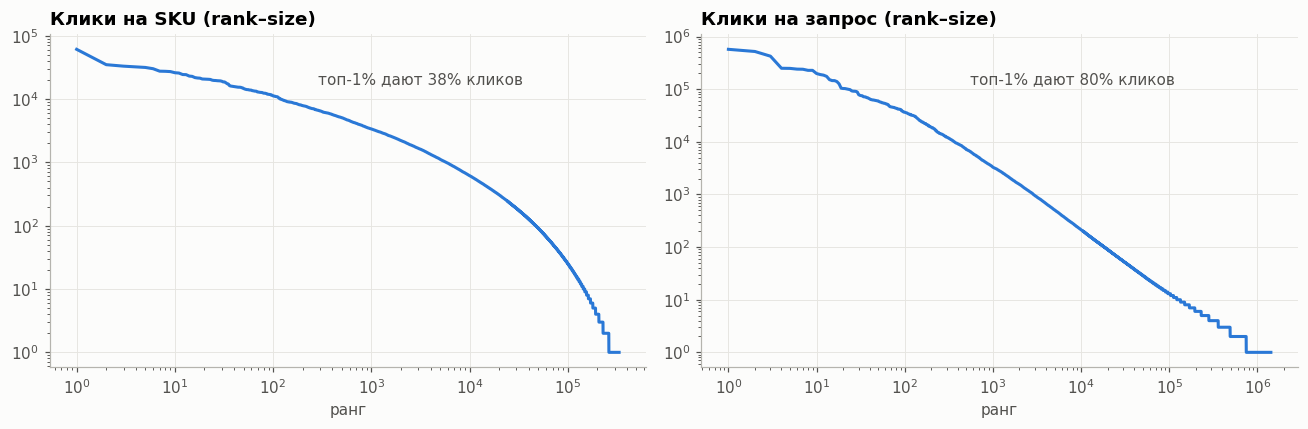

In [28]:
# дальше полная таблица атрибутов не нужна: оставляем срез по категориям раздела 8.1
w_offers = offers.offer_id[offers.leaf.isin(W_CATS)]
params_w = params.loc[params.offer_id.isin(w_offers) & params.is_search & ~params.service, ["offer_id", "param_name", "value"]]
params_w["offer_id"] = params_w.offer_id.astype(str); params_w["param_name"] = params_w.param_name.astype(str)
del desc, gr, sub_o, sub_p, params; free()
cs = clicks_sku.groupby("sku_id").clicks.sum()
qv = pd.read_parquet(DATA / "clicks_query.parquet").set_index("q").clicks.sort_values(ascending=False)
print(f"кликов: {cs.sum():,} | SKU с кликами: {len(cs):,} | уникальных запросов: {len(qv):,}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, s, t in [(axes[0], cs.sort_values(ascending=False), "Клики на SKU"), (axes[1], qv, "Клики на запрос")]:
    ax.loglog(np.arange(1, len(s) + 1), s.values, color=C[0], lw=2); ax.set_title(t + " (rank–size)"); ax.set_xlabel("ранг")
    top1 = s.head(max(1, len(s) // 100)).sum() / s.sum()
    ax.text(0.45, 0.85, f"топ-1% дают {top1:.0%} кликов", transform=ax.transAxes, color=INK2)
plt.tight_layout(); plt.show()

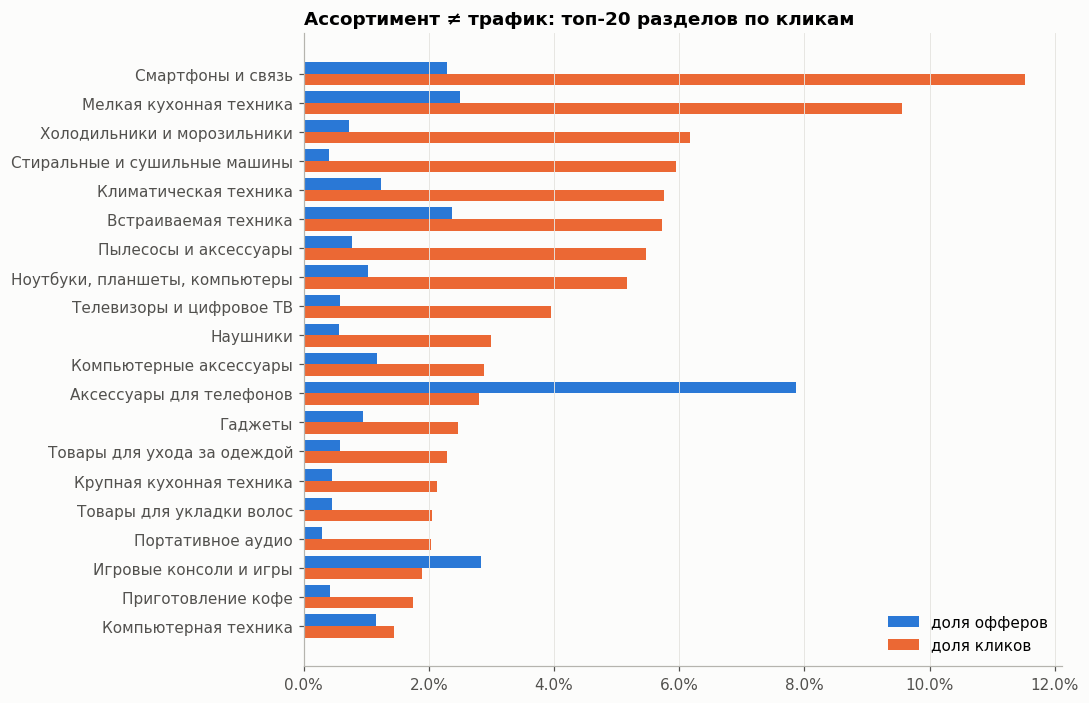

In [29]:
offers["clicks"] = offers.sku_id.map(cs).fillna(0)
l1 = offers.groupby("l1").agg(offers=("sku_id", "size"), clicks=("clicks", "sum"))
l1 = (l1 / l1.sum()).sort_values("clicks", ascending=False).head(20)
fig, ax = plt.subplots(figsize=(10, 6.5))
y = np.arange(len(l1)); h = 0.4
ax.barh(y - h/2, l1.offers, h, color=C[0], label="доля офферов"); ax.barh(y + h/2, l1.clicks, h, color=C[1], label="доля кликов")
ax.set_yticks(y, l1.index); ax.invert_yaxis(); ax.xaxis.set_major_formatter(pct); ax.legend(); ax.grid(axis="y", visible=False)
ax.set_title("Ассортимент ≠ трафик: топ-20 разделов по кликам"); plt.tight_layout(); plt.show()

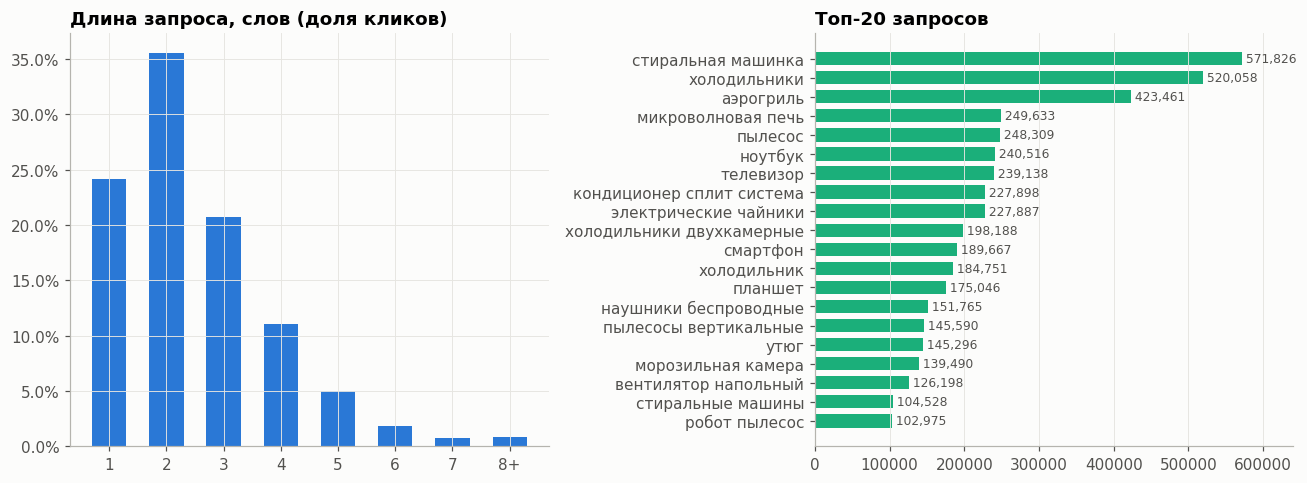

In [30]:
qlen = qv.index.str.count(" ").to_numpy() + 1  # запросы уже без крайних пробелов
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
lw = pd.Series(qv.values, index=np.minimum(qlen, 8)).groupby(level=0).sum() / qv.sum()
axes[0].bar(lw.index.astype(str).str.replace("8", "8+"), lw.values, color=C[0], width=0.6)
axes[0].yaxis.set_major_formatter(pct); axes[0].set_title("Длина запроса, слов (доля кликов)")
hbar(qv.head(20), ax=axes[1], title="Топ-20 запросов", color=C[2])
plt.tight_layout(); plt.show()
del qv, qlen; free()

### 8.1 Веса атрибутов по трафику
Для метрики «качество с учётом трафика» нужно знать, **по каким атрибутам реально ищут**. Берём пары (запрос, кликнутый SKU)
в ключевых категориях и проверяем, упоминает ли запрос значение атрибута **этого** SKU (бренд, память, цвет, диагональ…).
Доля кликов с упоминанием = вес атрибута.

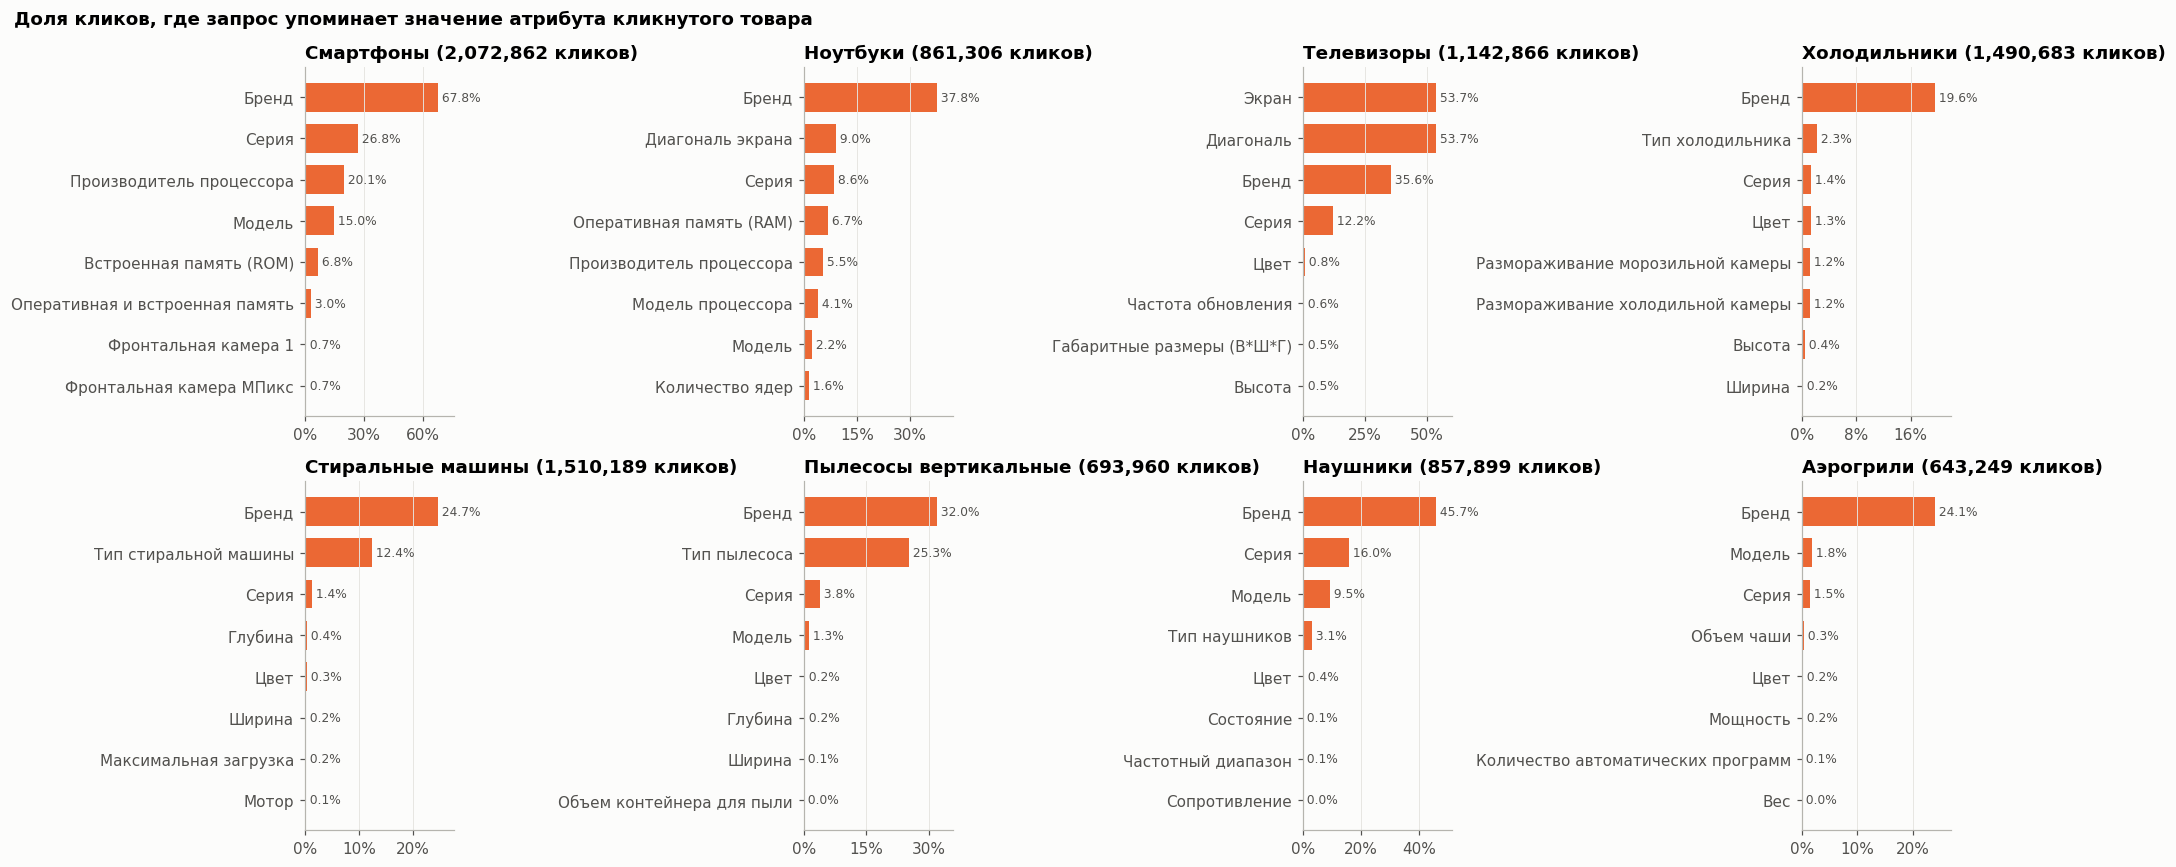

In [31]:
pairs = pd.read_parquet(DATA / "clicks_pairs.parquet")
pairs["sku_id"] = pairs.sku_id.astype("int64")
oinfo = offers.set_index("sku_id")[["offer_id", "leaf", "vendor"]]
pairs = pairs[pairs.sku_id.isin(oinfo.index)]
pairs = pairs.join(oinfo, on="sku_id")
pairs = pairs[pairs.leaf.isin(W_CATS)]

from functools import lru_cache

@lru_cache(maxsize=None)
def query_patterns(v):
    # скомпилированные шаблоны на значение: без кэша re перекомпилирует их на каждой паре
    v = norm_text(v).strip()
    if re.match(r"^\d", v):
        return tuple(re.compile(n) for n in num_needles(v))
    return (re.compile(rf"(?<!\w){re.escape(v)}(?!\w)"),) if len(v) >= 2 else ()

def in_query(v, q):
    return isinstance(v, str) and any(p.search(q) for p in query_patterns(v))

KEY_ATTRS = ["Модель_search", "Серия_search", "Цвет_search"]

def attr_weights(leaf, top_k=10):
    pp = pairs[pairs.leaf == leaf]
    sub = params_w[params_w.offer_id.isin(pp.offer_id.unique())]
    # кандидаты: самые заполненные _search-атрибуты категории + ключевые (модель, серия, цвет)
    fillc = sub.groupby("param_name").offer_id.nunique().sort_values(ascending=False)
    cand = pd.Index(fillc.head(25).index.tolist() + [a for a in KEY_ATTRS if a in fillc.index]).unique()
    vals = sub[sub.param_name.isin(cand)].drop_duplicates(["offer_id", "param_name"]).pivot(
        index="offer_id", columns="param_name", values="value")
    vals["Бренд"] = pp.drop_duplicates("offer_id").set_index("offer_id").vendor
    pp = pp.join(vals, on="offer_id")
    res = {}
    qn = pp.q.map(norm_text)
    for a in list(cand) + ["Бренд"]:
        hit = [in_query(v, q) for v, q in zip(pp[a], qn)]
        res[a.replace("_search", "")] = np.dot(hit, pp.clicks) / pp.clicks.sum()
    return pd.Series(res).sort_values(ascending=False).head(top_k), pp.clicks.sum()

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
weights = {}
for ax, leaf in zip(axes.flat, W_CATS):
    if (pairs.leaf == leaf).sum() == 0:
        ax.set_visible(False); continue
    s, n = attr_weights(leaf, 8)
    weights[leaf] = s
    hbar(s, ax=ax, title=f"{leaf} ({n:,.0f} кликов)", fmt="{:.1%}", color=C[1])
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0)); ax.xaxis.set_major_locator(mtick.MaxNLocator(3))
plt.suptitle("Доля кликов, где запрос упоминает значение атрибута кликнутого товара", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**Вывод 8.**
* Уникальных запросов 1.42 млн после `lower` + `strip` (в сырых данных 1.79 млн).
* Трафик сконцентрирован сильнее ассортимента: матрасы и чехлы дают много офферов, а клики уходят в крупную технику, смартфоны и ТВ.
  Поэтому **веса категорий и атрибутов для метрики берём из кликов**, а не из размера каталога.
* Запросы короткие (1–3 слова): категория плюс уточнение. Самое частое уточнение — **бренд** (20–68% кликов в зависимости от категории).
  Дальше идут атрибуты, специфичные для категории: **диагональ** у ТВ (~54%), **тип** у стиральных машин и пылесосов (12–25%),
  **серия и модель** у наушников и смартфонов, **память** у смартфонов и ноутбуков (5–7%).
* Цвет в запросах почти не встречается (<1.5%). Но по цвету фильтруют, а не печатают его, так что это нижняя оценка.
  Логов фильтров нет, поэтому веса из 8.1 сглаживаем к равномерным.
* Ограничение метода: дублирующие атрибуты совпадают с теми же словами запроса. «Производитель процессора» у смартфонов — это
  тот же Samsung или Apple, а «Экран» у ТВ — та же диагональ. Перед расчётом весов такие пары надо схлопывать.

## 9. Карточки без оффера: откуда взять категорию
Файл с предсказаниями нужен **по каждой карточке**, а у большинства карточек из `sku_desc` нет оффера в фиде — значит,
нет ни категории, ни схемы обязательных атрибутов. Проверяем, чем их можно закрыть:
`sku_seo_id` из кликов (если он совпадает с `categoryId`) и категорией по заголовку.

seo_id == categoryId у офферов с кликами: 97.2%


карточек в sku_desc: 1,177,200; без оффера: 935,845 (79%)
  из них с seo_id из кликов: 5.9%; восстановленные/уценённые: 6.3%


базлайн по заголовку (первые слова → категория), hold-out 48,414: покрытие 99.7%, accuracy 93.5%, accuracy на покрытых 93.7%


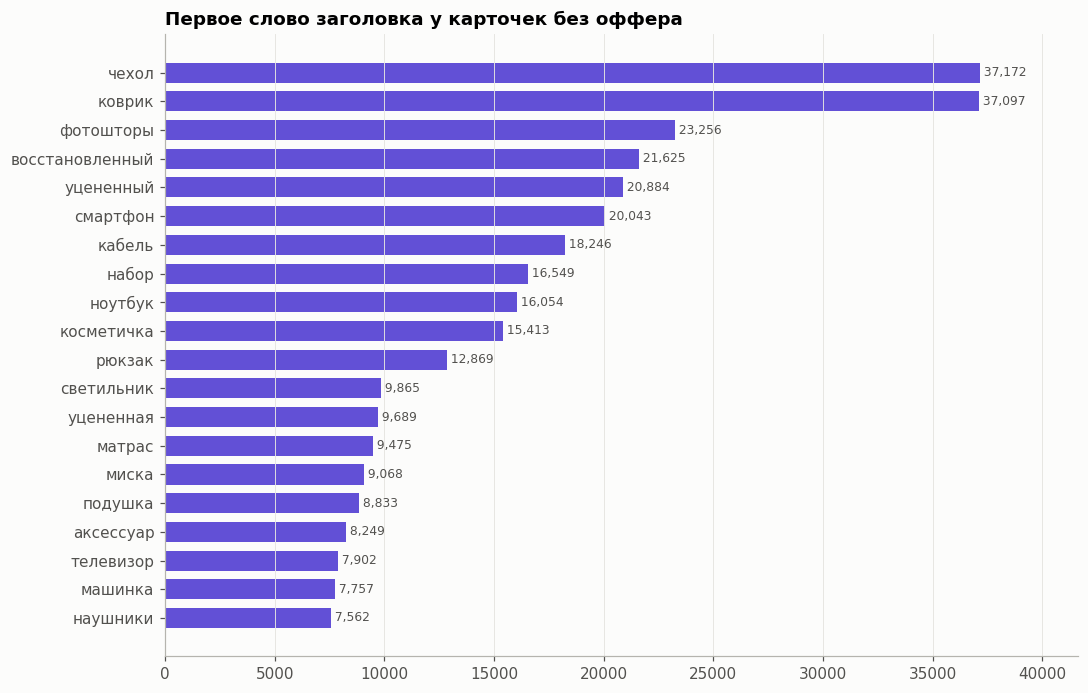

In [32]:
titles = pq.read_table(RAW / "sku_desc.parquet", columns=["sku_id", "title"]).to_pandas()
cat_of = offers.set_index("sku_id").category_id

# seo_id по SKU из кликов: читаем по row group'ам только два столбца
pf = pq.ParquetFile(RAW / "query_clicks.parquet")
seo_parts = []
for i in range(pf.num_row_groups):
    t = pf.read_row_group(i, columns=["sku_id", "sku_seo_id"])
    seo_parts.append(t.group_by("sku_id").aggregate([("sku_seo_id", "min")]))
seo = pa.concat_tables(seo_parts).group_by("sku_id").aggregate([("sku_seo_id_min", "min")]).to_pandas()
seo = seo.set_index(seo.sku_id.astype("int64"))["sku_seo_id_min_min"].astype(str)
del seo_parts; free()

known = seo[seo.index.isin(cat_of.index)]
print(f"seo_id == categoryId у офферов с кликами: {(known == cat_of.reindex(known.index)).mean():.1%}")

no_off = titles[~titles.sku_id.isin(cat_of.index)].copy()
no_off["seo"] = no_off.sku_id.map(seo)
tl = no_off.title.str.lower()
no_off["refurb"] = tl.str.match(r"(восстановлен|уценен)")
print(f"карточек в sku_desc: {len(titles):,}; без оффера: {len(no_off):,} ({len(no_off)/len(titles):.0%})")
print(f"  из них с seo_id из кликов: {no_off.seo.notna().mean():.1%}; восстановленные/уценённые: {no_off.refurb.mean():.1%}")

# базлайн «категория по заголовку»: первые 1–2 слова → самая частая категория среди офферов с описанием
def key(s, k):
    return s.str.lower().str.replace(r"^(восстановленн\w*|уцененн\w*)\s+", "", regex=True).str.split().str[:k].str.join(" ")
lab = titles[titles.sku_id.isin(cat_of.index)].assign(cat=lambda d: d.sku_id.map(cat_of))
test = (pd.util.hash_array(lab.sku_id.to_numpy()) % 5) == 0
tr, te = lab[~test], lab[test]
pred = pd.Series(index=te.index, dtype=object)
for k in (2, 1):  # сначала по двум словам, где их нет — по одному
    m = tr.assign(key=key(tr.title, k)).groupby("key").cat.agg(lambda s: s.mode().iloc[0])
    pred = pred.fillna(key(te.title, k).map(m))
print(f"базлайн по заголовку (первые слова → категория), hold-out {len(te):,}: "
      f"покрытие {pred.notna().mean():.1%}, accuracy {(pred == te.cat).mean():.1%}, "
      f"accuracy на покрытых {(pred[pred.notna()] == te.cat[pred.notna()]).mean():.1%}")
hbar(key(no_off.title, 1).value_counts().head(20), title="Первое слово заголовка у карточек без оффера", color=C[6])
plt.tight_layout(); plt.show()
del titles, lab, tr, te; free()

**Вывод 9.**
* 936 тыс. карточек (79% `sku_desc`) не имеют оффера, а значит, категории и схемы. `seo_id` из кликов совпадает
  с `categoryId` в 97% случаев, но есть только у 6% таких карточек.
* Простейший базлайн «первые 1–2 слова заголовка → самая частая категория» на отложенных офферах даёт покрытие 99.7%
  и accuracy 93.5%. Значит, шаг 0 пайплайна — категория: `seo_id`, где он есть, иначе классификатор по заголовку
  (этот базлайн, затем kNN по e5). Оценка оптимистична: среди карточек без оффера больше чехлов, ковриков и штор,
  чем в размеченной части.
* Ошибка категории даёт неверную схему, поэтому уверенность категории входит в уверенность атрибутов: при низкой
  уверенности извлекаем только сквозные атрибуты (бренд, цвет, размеры, вес).
* 6% карточек без оффера — восстановленные и уценённые с шаблонными описаниями: для них источник атрибутов — только заголовок.

## 10. Итог

* **Разметка уже есть в фиде.** `_search` — сырое значение, которое извлекаем; фасет — каноническое значение для фильтров,
  к нему нормализуем. Сами фасеты нужно предварительно почистить (`черный`/`чёрный`, заглушки `другой`/`другие цвета` — 18% цветов).
* **Большинство карточек без категории.** 79% `sku_desc` нет в фиде; категорию восстанавливаем по `seo_id` или по заголовку (базлайн 93.5%).
* **Длинный хвост.** 3.6 тыс. категорий, медиана 10 офферов: схема категории выводится автоматически,
  для мелких категорий берётся от родителя, метрики считаем macro по категориям.
* **Не всё есть в тексте.** Бренд и память — в заголовке, CPU и SSD — в описании, цвет часто только после словаря синонимов,
  диагональ и батарея смартфона отсутствуют в тексте почти у всех восстановленных и уценённых карточек.
  Recall считаем отдельно на grounded-подмножестве.
* **Трафик.** Ищут прежде всего по бренду, дальше по ключевому атрибуту категории: диагональ, тип, серия, память.
  Отсюда веса для traffic-weighted F1.
* **Сплит.** Stratified по листовой категории + отложенные целиком категории (проверка на новых) + дубли описаний и
  варианты одной модели (vendor + model без цвета) в одном фолде.

## Для презы

| В данных / задаче | Мы делаем |
|---|---|
| Метки уже есть в фиде: сырое значение (`_search`) + канон для фильтров (фасет) | Обучаем и оцениваем на 241 тыс. карточек без ручной разметки; фасеты после чистки — справочник нормализации |
| 79% карточек нет в фиде: нет категории и схемы | Шаг 0 — категория: `seo_id` из кликов или классификатор по заголовку (базлайн 93.5%) |
| Отдельного поля «атрибуты продавца» нет: все атрибуты фида — это ответы | На вход только заголовок и описание; роль атрибутов продавца играют блоки «Характеристики» / «Ключ: значение» (у 36–38% карточек без оффера) |
| `vendor` и `model` в фиде делают бренд и модель тривиальными | Считаем два режима: с полями продавца и без них |
| 3.6 тыс. категорий, у половины < 10 товаров; больше всего не электроника, а матрасы и шторы | Схема категории строится автоматически, хвост наследует её от родителя; общие правила для размеров, веса, материала, цвета |
| Описание есть только у 44% товаров | Пайплайн работает и по одному заголовку |
| Бренд и память почти всегда в заголовке | Закрываем правилами по заголовку — дёшево, без LLM |
| CPU и SSD чаще только в описании | Парсер «ключ: значение» и regex по описанию |
| Цвет — >1.5 тыс. вариантов записи (`Titanium Grey`, «мятный»), 18% фасетов — заглушки | Словарь синонимов рус/англ + e5-retrieval к канону; заглушки = пропуск |
| Числа в разных единицах, единица часто в `@unit`, фасеты — корзины (`3000-5000 мАч`) | Канон — число с единицей (`1 ТБ` = `1024 ГБ`); корзину для фильтра выводим правилом |
| 49 атрибутов бывают многозначными | Предсказываем множество, метрика — F1 по множеству |
| Диагонали и батареи смартфона нет в тексте у восстановленных и уценённых | Не выдумываем: берём из карточек той же модели отдельным источником с флагом и пониженной уверенностью или отдаём на ручную проверку |
| LLM дорогая, а пустое поле обычно значит «в тексте нет» | Зовём LLM только при зацепке в тексте (частичное совпадение, конфликт источников); ответ проходит grounding-проверку после нормализации |
| Покупатели ищут по бренду, диагонали, типу, серии | Взвешиваем метрику по кликам: ошибки в этих атрибутах стоят дороже |
| ТЗ: показать вклад каждого шага, качество на хвосте и новых категориях | Ablation: правила → + retrieval → + LLM; F1 macro по категориям; тест на отложенных категориях; дубли и варианты модели в одном фолде |
| 2 тыс. продавцов; диапазон ID не совпадает с 1P/3P | Метрики по срезам 1P/3P (по полю «Продавец») и размеру продавца — качество одинаково для всех |